# KA SS 26 · Challenge 2 — **Stage 4: CoCo, higher resolution, ensemble partner**

Same proven pipeline as Stage 3, with three deliberate differences so that this run is
useful whichever way the rules question lands:

1. **`WEIGHTS_MODE = "imagenet_bb"`** — only the ResNet-50 backbone is pretrained; FPN,
   RPN, box head and mask head start from scratch. This is compliant under the
   strictest reading of "only generic pretrained weights", so it is the insurance
   policy if a TA rules COCO detector weights out.
2. **Higher resolution** (train 768–896, test 864, max 1536) and a different seed.
   Together with the different initialisation this produces genuinely different
   errors, which is what an ensemble needs.
3. **Ensemble section at the end** — attach the Stage 3 notebook output under
   *Add Data → Your Work → Notebook Output* and this run will merge both prediction
   caches, retune the threshold on the shared validation fold, and write
   `submission_ensemble.csv` only if it actually beats both single models.

**Both notebooks use fold 0 on purpose.** Different folds would make the ensemble
threshold impossible to tune honestly, because each model would have trained on the
other's validation images.

**If a TA confirms COCO weights are allowed before you launch this:** change
`WEIGHTS_MODE` to `"coco"` in the config cell. It then becomes a pure diversity run
(different seed, resolution and augmentation draw) and will score higher on its own.

Expected runtime: about 2.5 h.


## 0 · Environment, deterministic setup, and output directories


In [1]:
import os

# Must be set before torch is imported. Kaggle may allocate T4 x2; this run uses only cuda:0.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import sys
import gc
import json
import time
import math
import random
import warnings
import shutil
from glob import glob
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
T_START = time.time()

def elapsed_seconds():
    return time.time() - T_START

def format_duration(seconds):
    seconds = int(seconds)
    return f"{seconds // 3600}h {(seconds % 3600) // 60:02d}m"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
torch.backends.cudnn.benchmark = True

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ART = Path("/kaggle/working/artifacts")
CKPT = Path("/kaggle/working/checkpoints")
ART.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("device      :", DEVICE)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("gpu         :", torch.cuda.get_device_name(0))
    print("gpu memory  :", f"{props.total_memory / 1e9:.1f} GB")
print("cpu count   :", os.cpu_count())


python      : 3.12.13
torch       : 2.10.0+cu128
torchvision : 0.25.0+cu128
device      : cuda
gpu         : Tesla T4
gpu memory  : 15.6 GB
cpu count   : 4


## 1 · Configuration


In [2]:
class CFG:
    # Run
    SEED = 777
    SMOKE_TEST = False
    TOTAL_BUDGET_SEC = 10.0 * 3600
    RESERVE_SEC = 45 * 60

    # Data
    VAL_FRACTION = 0.15
    IMG_H = 520
    IMG_W = 704
    RLE_ORDER = "auto"
    MIN_GT_AREA = 10
    MAX_INSTANCES_TRAIN = None

    # Official metric
    PRIMARY_METRIC = "f1"
    DICE_MATCH_THR = 0.50

    # Model
    ARCH = "v2"
    WEIGHTS_MODE = "coco"        # was "imagenet_bb"
    TRAINABLE_BACKBONE_LAYERS = 5
    MIN_SIZE_TRAIN = (768, 832, 896)
    MIN_SIZE_TEST = 864
    MAX_SIZE = 1536
    NORMALIZE_WITH_DATASET_STATS = False  # False preserves pretrained ImageNet normalization

    # Filled from EDA
    ANCHOR_SIZES = "auto"
    ASPECT_RATIOS = "auto"
    ANCHOR_SCALE_CORRECTION = True
    BOX_DET_PER_IMG = 850
    CACHE_MAX_DET = None
    EVAL_MAX_DET = None

    # Detection internals
    RPN_PRE_TEST = 4000
    RPN_POST_TEST = 2500
    RPN_BATCH_PER_IMG = 512
    BOX_BATCH_PER_IMG = 512
    BOX_NMS_THR = 0.60

    # Loss
    MASK_LOSS = "bce+dice"
    BCE_W = 1.0
    DICE_W = 1.0

    # Optimization
    EPOCHS = 40
    BATCH_SIZE = 1
    ACCUM_STEPS = 4
    LR = 1.5e-4                  # was 2.5e-4
    BACKBONE_LR_MULT = 0.5       # was 0.3
    WEIGHT_DECAY = 1e-4
    WARMUP_STEPS = 300           # was 500
    GRAD_CLIP = 5.0
    AMP = True
    NUM_WORKERS = 2

    # Evaluation schedule
    EVAL_START_EPOCH = 3         # was 6
    EVAL_EVERY_EARLY = 4
    EVAL_DENSE_FROM = 28
    EVAL_SCORE_GRID = tuple(np.round(np.arange(0.10, 0.91, 0.10), 2))
    EVAL_MASK_THR = 0.50
    EVAL_MIN_AREA = 50

    # Augmentation
    AUG_HFLIP = 0.5
    AUG_VFLIP = 0.5
    AUG_ROT90 = 0.5
    AUG_BRIGHTNESS_CONTRAST = 0.5
    AUG_GAMMA = 0.3
    AUG_NOISE = 0.2

    # Final cache and sweep
    CACHE_SCORE_THR = 0.01
    SWEEP_MASK_THR = (0.30, 0.40, 0.50, 0.60)
    SWEEP_SCORE_THR = tuple(np.round(np.arange(0.02, 0.99, 0.02), 2))
    SWEEP_MIN_AREA_Q = (0.00, 0.01, 0.03, 0.06, 0.10)
    SWEEP_ALLOW_OVERLAP = (False, True)

    # Image-cluster thresholding
    CLUSTER_K_RANGE = (2, 3, 4, 5)
    PER_CLUSTER_THRESHOLDS = "auto"
    PER_CLUSTER_MIN_VAL = 10
    PER_CLUSTER_MIN_GAIN = 0.010

    # Submission
    SUB_INDEX_COL = "idx"
    FALLBACK_TO_TOP_DETECTION = True

    # ---------------- Stage 3/4 additions ----------------
    RUN_TAG = "stage4_imagenet_r50v2_hires"
    # Grouped validation: images from the same field of view / time-lapse series are
    # near-duplicates. A random split puts them on both sides and inflates val F1.
    GROUP_SPLIT = True
    DUP_CORR_THR = 0.72       # normalised cross-correlation above this -> same group
    N_FOLDS = 5
    FOLD = 0                  # BOTH notebooks use fold 0 so the ensemble can be tuned honestly
    # Detection capacity floor (dataset max is 782 instances/image)
    DET_CAP_FLOOR = 1000
    # Threshold selection: take the centre of the plateau, not the argmax spike
    ROBUST_THRESHOLD = True
    ROBUST_TOL = 0.004
    # Artefacts for leaderboard probing and for the cross-notebook ensemble
    SAVE_CACHES = True
    PROBE_DELTAS = (-0.12, -0.06, 0.06, 0.12)

if CFG.SMOKE_TEST:
    CFG.EPOCHS = 2
    CFG.EVAL_START_EPOCH = 1
    CFG.EVAL_EVERY_EARLY = 1
    CFG.EVAL_DENSE_FROM = 1
    CFG.MIN_SIZE_TRAIN = (704,)
    CFG.SWEEP_MASK_THR = (0.40, 0.50)
    CFG.SWEEP_SCORE_THR = tuple(np.round(np.arange(0.10, 0.91, 0.10), 2))
    CFG.SWEEP_MIN_AREA_Q = (0.00, 0.05)
    CFG.SWEEP_ALLOW_OVERLAP = (False,)

seed_everything(CFG.SEED)
STATS = {}

print("SMOKE_TEST    :", CFG.SMOKE_TEST)
print("epochs        :", CFG.EPOCHS)
print("primary metric:", CFG.PRIMARY_METRIC)
print("time budget   :", format_duration(CFG.TOTAL_BUDGET_SEC))


SMOKE_TEST    : False
epochs        : 40
primary metric: f1
time budget   : 10h 00m


## 2 · Dataset discovery and schema validation


In [3]:
from PIL import Image

def find_dataset_root():
    roots = []
    for csv_path in Path("/kaggle/input").rglob("train.csv"):
        root = csv_path.parent
        if (root / "train").is_dir() and (root / "test").is_dir():
            roots.append(root)
    if not roots:
        raise FileNotFoundError(
            "Could not find a directory containing train.csv, train/, and test/ under /kaggle/input"
        )
    roots = sorted(set(roots), key=lambda p: (len(str(p)), str(p)))
    print("dataset candidates:")
    for r in roots:
        print(" ", r)
    return roots[0]

BASE = find_dataset_root()
TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"
UNLAB_DIR = BASE / "unlabeled_additional_data"
TRAIN_CSV = BASE / "train.csv"

print("\nselected BASE:", BASE)
print("contents:")
for p in sorted(BASE.iterdir()):
    if p.is_dir():
        print(f"  [dir ] {p.name:<32} {len(list(p.glob('*')))} files")
    else:
        print(f"  [file] {p.name:<32} {p.stat().st_size / 1e6:.2f} MB")

sample_candidates = list(BASE.glob("*submission*.csv")) + list(Path("/kaggle/input").rglob("*sample_submission*.csv"))
SAMPLE_SUB = sample_candidates[0] if sample_candidates else None
if SAMPLE_SUB:
    sample_df = pd.read_csv(SAMPLE_SUB)
    print("\nsample submission:", SAMPLE_SUB)
    print("columns:", sample_df.columns.tolist(), "rows:", len(sample_df))
    print(sample_df.head(3).to_string())
else:
    print("\nNo sample submission found. The notebook will use idx, id, annotation.")


dataset candidates:
  /kaggle/input/competitions/ka-ss-26-challenge-2/cells_segmentation

selected BASE: /kaggle/input/competitions/ka-ss-26-challenge-2/cells_segmentation
contents:
  [dir ] test                             182 files
  [dir ] train                            424 files
  [file] train.csv                        13.35 MB
  [dir ] unlabeled_additional_data        1972 files

No sample submission found. The notebook will use idx, id, annotation.


In [4]:
df_raw = pd.read_csv(TRAIN_CSV)
print("shape  :", df_raw.shape)
print("columns:", df_raw.columns.tolist())
print("dtypes :\n", df_raw.dtypes.to_string())
print("\nhead:\n", df_raw.head(3).to_string())

ID_COL = next(
    (c for c in df_raw.columns if c.lower() in ("id", "image_id", "imageid")),
    None,
)
ANN_COL = next(
    (c for c in df_raw.columns if c.lower() in ("annotation", "encodedpixels", "rle", "segmentation")),
    None,
)
assert ID_COL is not None and ANN_COL is not None, (
    f"Could not identify id and annotation columns in {df_raw.columns.tolist()}"
)

OTHER_COLS = [c for c in df_raw.columns if c not in (ID_COL, ANN_COL)]
CELL_TYPE_COL = next(
    (
        c
        for c in OTHER_COLS
        if df_raw[c].dtype == object and 1 < df_raw[c].nunique(dropna=True) <= 12
    ),
    None,
)
HAS_CELL_TYPE = CELL_TYPE_COL is not None

print("\nID_COL       :", ID_COL)
print("ANN_COL      :", ANN_COL)
print("other columns:", OTHER_COLS)
print("cell type    :", CELL_TYPE_COL)
print("unique images:", df_raw[ID_COL].nunique())
print("annotation rows:", len(df_raw))

STATS["csv_columns"] = df_raw.columns.tolist()
STATS["has_cell_type"] = bool(HAS_CELL_TYPE)
STATS["n_annotations"] = int(len(df_raw))
STATS["n_train_images"] = int(df_raw[ID_COL].nunique())


shape  : (53065, 3)
columns: ['Unnamed: 0', 'id', 'annotation']
dtypes :
 Unnamed: 0     int64
id            object
annotation    object

head:
    Unnamed: 0            id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [5]:
def folder_report(folder, inspect_all=True):
    files = sorted(folder.glob("*.png"))
    probe = files if inspect_all else files[:200]
    sizes = Counter()
    for path in probe:
        with Image.open(path) as im:
            sizes[(im.size[1], im.size[0])] += 1
    return files, sizes

train_files, train_sizes = folder_report(TRAIN_DIR)
test_files, test_sizes = folder_report(TEST_DIR)
if UNLAB_DIR.exists():
    unlab_files, unlab_sizes = folder_report(UNLAB_DIR, inspect_all=False)
else:
    unlab_files, unlab_sizes = [], Counter()

for name, files, sizes in [
    ("train", train_files, train_sizes),
    ("test", test_files, test_sizes),
    ("unlabeled", unlab_files, unlab_sizes),
]:
    print(f"{name:<10} {len(files):>5} images | sizes(H,W): {dict(sizes)}")

assert len(train_sizes) == 1, f"Mixed train image sizes: {train_sizes}"
assert len(test_sizes) == 1, f"Mixed test image sizes: {test_sizes}"
(H, W), _ = train_sizes.most_common(1)[0]
CFG.IMG_H, CFG.IMG_W = int(H), int(W)

TRAIN_IDS = sorted(path.stem for path in train_files)
TEST_IDS = sorted(path.stem for path in test_files)

STATS["img_hw"] = [CFG.IMG_H, CFG.IMG_W]
STATS["n_test_images"] = len(TEST_IDS)
STATS["n_unlabeled"] = len(list(UNLAB_DIR.glob("*.png"))) if UNLAB_DIR.exists() else 0

print("\nresolved shape:", (CFG.IMG_H, CFG.IMG_W))

# A harmless placeholder ensures that a failed commit still exposes a CSV.
placeholder = pd.DataFrame(
    {
        CFG.SUB_INDEX_COL: np.arange(len(TEST_IDS)),
        ID_COL: TEST_IDS,
        ANN_COL: ["-1"] * len(TEST_IDS),
    }
)
placeholder.to_csv("/kaggle/working/submission.csv", index=False)
print("placeholder /kaggle/working/submission.csv written; it will be overwritten after inference")


train        424 images | sizes(H,W): {(520, 704): 424}
test         182 images | sizes(H,W): {(520, 704): 182}
unlabeled   1972 images | sizes(H,W): {(520, 704): 200}

resolved shape: (520, 704)
placeholder /kaggle/working/submission.csv written; it will be overwritten after inference


## 3 · RLE order detection, round-trip validation, and annotation cache


In [6]:
from scipy import ndimage as ndi

def rle_decode_flat(rle, h, w, order="C"):
    if not isinstance(rle, str) or not rle.strip() or rle.strip() == "-1":
        return np.empty(0, dtype=np.int64)

    values = np.fromstring(rle, sep=" ", dtype=np.int64)
    if values.size % 2 != 0:
        raise ValueError("RLE must contain start/length pairs")

    starts = values[0::2] - 1
    lengths = values[1::2]
    parts = [np.arange(start, start + length, dtype=np.int64) for start, length in zip(starts, lengths)]
    idx = np.concatenate(parts) if parts else np.empty(0, dtype=np.int64)

    if order == "C":
        return idx

    # Convert Fortran-linear indices to row-major indices.
    return (idx % h) * w + (idx // h)

def rle_encode(mask_bool):
    pixels = np.asarray(mask_bool, dtype=np.uint8).reshape(-1)
    padded = np.concatenate(([0], pixels, [0]))
    runs = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    runs[1::2] -= runs[0::2]
    return " ".join(map(str, runs.tolist()))

def flat_to_mask(flat, h, w):
    mask = np.zeros(h * w, dtype=bool)
    mask[np.asarray(flat, dtype=np.int64)] = True
    return mask.reshape(h, w)

valid_rows = df_raw[
    df_raw[ANN_COL].notna()
    & (df_raw[ANN_COL].astype(str).str.strip() != "")
    & (df_raw[ANN_COL].astype(str).str.strip() != "-1")
]
probe = valid_rows.sample(min(300, len(valid_rows)), random_state=CFG.SEED)

order_report = {}
for order in ("C", "F"):
    components = []
    fill_ratios = []
    out_of_bounds = 0

    for rle in probe[ANN_COL].astype(str):
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, order)
        if flat.size == 0:
            continue
        if flat.min() < 0 or flat.max() >= CFG.IMG_H * CFG.IMG_W:
            out_of_bounds += 1
            continue

        mask = flat_to_mask(flat, CFG.IMG_H, CFG.IMG_W)
        _, n_components = ndi.label(mask)
        components.append(n_components)

        ys, xs = np.nonzero(mask)
        box_area = (ys.max() - ys.min() + 1) * (xs.max() - xs.min() + 1)
        fill_ratios.append(mask.sum() / max(box_area, 1))

    order_report[order] = {
        "mean_components": float(np.mean(components)),
        "pct_single_component": float(np.mean(np.asarray(components) == 1) * 100),
        "mean_fill_ratio": float(np.mean(fill_ratios)),
        "out_of_bounds": int(out_of_bounds),
    }

print(pd.DataFrame(order_report).T.to_string())

if CFG.RLE_ORDER == "auto":
    CFG.RLE_ORDER = max(
        order_report,
        key=lambda order: (
            order_report[order]["pct_single_component"],
            order_report[order]["mean_fill_ratio"],
        ),
    )

print("\nRLE_ORDER:", CFG.RLE_ORDER)

probe_rle = str(probe.iloc[0][ANN_COL])
probe_flat = rle_decode_flat(probe_rle, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
probe_mask = flat_to_mask(probe_flat, CFG.IMG_H, CFG.IMG_W)
round_trip = rle_decode_flat(rle_encode(probe_mask), CFG.IMG_H, CFG.IMG_W, "C")
assert np.array_equal(np.sort(probe_flat), np.sort(round_trip)), "RLE round-trip failed"

STATS["rle_order_report"] = order_report
STATS["rle_order"] = CFG.RLE_ORDER
print("round-trip: passed")


   mean_components  pct_single_component  mean_fill_ratio  out_of_bounds
C         1.576667             95.666667         0.567231            0.0
F        26.453333              0.000000         0.018753            0.0

RLE_ORDER: C
round-trip: passed


In [7]:
t0 = time.time()
INST = defaultdict(list)
bad_rows = 0

for image_id, rle in zip(df_raw[ID_COL].astype(str), df_raw[ANN_COL].astype(str)):
    rle = rle.strip()
    if rle in ("", "-1", "nan"):
        continue
    try:
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
    except Exception:
        bad_rows += 1
        continue
    if flat.size == 0 or flat.min() < 0 or flat.max() >= CFG.IMG_H * CFG.IMG_W:
        bad_rows += 1
        continue
    INST[image_id].append(flat.astype(np.int32))

print(
    f"decoded {sum(len(v) for v in INST.values())} instances "
    f"across {len(INST)} images in {time.time() - t0:.1f}s; bad/skipped={bad_rows}"
)

overlap_image_count = 0
overlap_fractions = []
overlap_probe_ids = list(INST)[:120]
for image_id in overlap_probe_ids:
    accumulator = np.zeros(CFG.IMG_H * CFG.IMG_W, dtype=np.int16)
    for flat in INST[image_id]:
        accumulator[flat] += 1
    overlap_pixels = int((accumulator > 1).sum())
    overlap_image_count += int(overlap_pixels > 0)
    foreground_pixels = max(int((accumulator > 0).sum()), 1)
    overlap_fractions.append(overlap_pixels / foreground_pixels)

overlap_pct = 100 * overlap_image_count / max(len(overlap_probe_ids), 1)
print(f"images with GT overlap in probe: {overlap_pct:.1f}%")
print(f"mean overlap fraction of foreground: {100 * np.mean(overlap_fractions):.3f}%")

STATS["gt_overlap_images_pct"] = float(overlap_pct)
STATS["gt_overlap_fg_fraction"] = float(np.mean(overlap_fractions))


decoded 53065 instances across 424 images in 2.9s; bad/skipped=0
images with GT overlap in probe: 91.7%
mean overlap fraction of foreground: 1.128%


## 4 · EDA-driven detection capacity, areas, and resize-corrected anchors


In [8]:
counts = np.asarray([len(INST[image_id]) for image_id in TRAIN_IDS if image_id in INST])
areas = []
box_widths = []
box_heights = []

for instances in INST.values():
    for flat in instances:
        ys, xs = np.divmod(flat, CFG.IMG_W)
        areas.append(flat.size)
        box_widths.append(xs.max() - xs.min() + 1)
        box_heights.append(ys.max() - ys.min() + 1)

areas = np.asarray(areas)
box_widths = np.asarray(box_widths)
box_heights = np.asarray(box_heights)
box_side = np.sqrt(box_widths.astype(float) * box_heights)
aspect = box_heights / np.maximum(box_widths, 1)

def percentile_report(values, percentiles=(0, 1, 5, 25, 50, 75, 95, 99, 100)):
    return {
        f"p{p}": float(np.percentile(values, p))
        for p in percentiles
    }

print("instances per image:", {k: round(v, 1) for k, v in percentile_report(counts).items()})
print("instance area      :", {k: round(v, 1) for k, v in percentile_report(areas).items()})
print("box sqrt(w*h)      :", {k: round(v, 1) for k, v in percentile_report(box_side).items()})
print("aspect h/w         :", {k: round(v, 2) for k, v in percentile_report(aspect).items()})

STATS["counts"] = percentile_report(counts)
STATS["areas"] = percentile_report(areas)
STATS["box_side"] = percentile_report(box_side)
STATS["aspect"] = percentile_report(aspect)

# p99 × 1.4, rounded to 50, with an upper safety limit.
derived_cap = int(np.ceil(np.percentile(counts, 99) * 1.4 / 50) * 50)
CFG.BOX_DET_PER_IMG = int(np.clip(derived_cap, 300, 1000))
CFG.CACHE_MAX_DET = CFG.BOX_DET_PER_IMG if CFG.CACHE_MAX_DET is None else CFG.CACHE_MAX_DET
CFG.EVAL_MAX_DET = CFG.BOX_DET_PER_IMG if CFG.EVAL_MAX_DET is None else CFG.EVAL_MAX_DET

print(
    f"\nBOX_DET_PER_IMG = CACHE_MAX_DET = EVAL_MAX_DET = {CFG.BOX_DET_PER_IMG} "
    f"(p95={np.percentile(counts, 95):.0f}, p99={np.percentile(counts, 99):.0f}, max={counts.max()})"
)

# Anchors are generated after GeneralizedRCNNTransform resizes the image.
train_scales = [
    min(size / CFG.IMG_H, CFG.MAX_SIZE / CFG.IMG_W)
    for size in CFG.MIN_SIZE_TRAIN
]
scale_train = float(np.median(train_scales))
scale_test = float(min(CFG.MIN_SIZE_TEST / CFG.IMG_H, CFG.MAX_SIZE / CFG.IMG_W))
anchor_scale = 0.5 * (scale_train + scale_test) if CFG.ANCHOR_SCALE_CORRECTION else 1.0

if CFG.ANCHOR_SIZES == "auto":
    raw_sizes = np.percentile(box_side, [8, 25, 50, 78, 96])
    resized_sizes = raw_sizes * anchor_scale
    sizes = [int(max(8, round(size / 4) * 4)) for size in resized_sizes]
    for i in range(1, len(sizes)):
        sizes[i] = max(sizes[i], sizes[i - 1] + 4)
    CFG.ANCHOR_SIZES = tuple((size,) for size in sizes)

if CFG.ASPECT_RATIOS == "auto":
    lo, hi = np.percentile(aspect, [15, 85])
    CFG.ASPECT_RATIOS = (
        float(round(max(0.2, min(lo, 0.8)), 2)),
        1.0,
        float(round(min(5.0, max(hi, 1.25)), 2)),
    )

MIN_AREA_GRID = sorted(
    set(int(np.percentile(areas, q * 100)) for q in CFG.SWEEP_MIN_AREA_Q)
)

print(f"resize scale train≈{scale_train:.3f}, test≈{scale_test:.3f}, anchor scale={anchor_scale:.3f}")
print("ANCHOR_SIZES  :", CFG.ANCHOR_SIZES)
print("ASPECT_RATIOS :", CFG.ASPECT_RATIOS)
print("min-area grid :", MIN_AREA_GRID)

STATS["anchor_scale"] = float(anchor_scale)
STATS["anchor_sizes"] = str(CFG.ANCHOR_SIZES)
STATS["aspect_ratios"] = str(CFG.ASPECT_RATIOS)


instances per image: {'p0': 5.0, 'p1': 11.0, 'p5': 17.0, 'p25': 29.0, 'p50': 47.5, 'p75': 144.2, 'p95': 503.8, 'p99': 592.8, 'p100': 782.0}
instance area      : {'p0': 30.0, 'p1': 53.0, 'p5': 82.0, 'p25': 145.0, 'p50': 215.0, 'p75': 341.0, 'p95': 920.0, 'p99': 2123.4, 'p100': 13327.0}
box sqrt(w*h)      : {'p0': 6.0, 'p1': 8.9, 'p5': 11.0, 'p25': 15.0, 'p50': 18.8, 'p75': 25.5, 'p95': 54.1, 'p99': 89.4, 'p100': 314.4}
aspect h/w         : {'p0': 0.02, 'p1': 0.29, 'p5': 0.44, 'p25': 0.74, 'p50': 1.0, 'p75': 1.33, 'p95': 2.21, 'p99': 3.34, 'p100': 12.56}

BOX_DET_PER_IMG = CACHE_MAX_DET = EVAL_MAX_DET = 850 (p95=504, p99=593, max=782)
resize scale train≈1.600, test≈1.662, anchor scale=1.631
ANCHOR_SIZES  : ((20,), (24,), (32,), (44,), (96,))
ASPECT_RATIOS : (0.62, 1.0, 1.58)
min-area grid : [30, 53, 71, 87, 103]


In [9]:
# Detection capacity floor: the dataset reaches 782 instances in one image and
# Stage 2 never predicted more than 476, so recall was capacity-bound on dense images.
CFG.BOX_DET_PER_IMG = int(max(CFG.BOX_DET_PER_IMG, CFG.DET_CAP_FLOOR))
CFG.CACHE_MAX_DET = CFG.BOX_DET_PER_IMG
CFG.EVAL_MAX_DET = CFG.BOX_DET_PER_IMG
print(">>> detections/image raised to", CFG.BOX_DET_PER_IMG)
print(">>> max instances kept per training image:",
      CFG.MAX_INSTANCES_TRAIN if CFG.MAX_INSTANCES_TRAIN else "all")


>>> detections/image raised to 1000
>>> max instances kept per training image: all


In [10]:
def load_gray01(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("L"), dtype=np.float32) / 255.0

def image_features(path):
    with Image.open(path) as image:
        arr = np.asarray(image.convert("L"), dtype=np.float32)

    histogram = np.histogram(arr, bins=24, range=(0, 255))[0].astype(np.float32)
    histogram /= max(histogram.sum(), 1)
    laplacian = ndi.laplace(arr)

    summary = np.asarray(
        [
            arr.mean(),
            arr.std(),
            np.percentile(arr, 1),
            np.percentile(arr, 25),
            np.percentile(arr, 50),
            np.percentile(arr, 75),
            np.percentile(arr, 99),
            laplacian.var(),
            np.abs(np.diff(arr, axis=0)).mean(),
            np.abs(np.diff(arr, axis=1)).mean(),
        ],
        dtype=np.float32,
    )
    return np.concatenate([summary, histogram])

t0 = time.time()
FEATURES = {}
for path in train_files + test_files:
    FEATURES[path.stem] = image_features(path)
print(f"computed image features for {len(FEATURES)} train+test images in {time.time() - t0:.1f}s")

pixel_sum = 0.0
pixel_sq_sum = 0.0
pixel_count = 0
for path in train_files[:200]:
    arr = load_gray01(path).astype(np.float64)
    pixel_sum += arr.sum()
    pixel_sq_sum += np.square(arr).sum()
    pixel_count += arr.size

DS_MEAN = float(pixel_sum / pixel_count)
DS_STD = float(np.sqrt(max(pixel_sq_sum / pixel_count - DS_MEAN ** 2, 1e-12)))
print(f"dataset mean/std: {DS_MEAN:.4f}/{DS_STD:.4f}")
print("model normalization:", "dataset statistics" if CFG.NORMALIZE_WITH_DATASET_STATS else "pretrained ImageNet defaults")

STATS["ds_mean"] = DS_MEAN
STATS["ds_std"] = DS_STD


computed image features for 606 train+test images in 25.9s
dataset mean/std: 0.5018/0.0543
model normalization: pretrained ImageNet defaults


## 5 · Image clusters for stratification and optional cluster-specific thresholds


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feature_ids = list(FEATURES)
feature_matrix = np.stack([FEATURES[image_id] for image_id in feature_ids])

SCALER = StandardScaler()
scaled_features = SCALER.fit_transform(feature_matrix)
PCA_MODEL = PCA(n_components=6, random_state=CFG.SEED)
pca_features = PCA_MODEL.fit_transform(scaled_features)

silhouette = {}
for k in CFG.CLUSTER_K_RANGE:
    candidate = KMeans(n_clusters=k, n_init=20, random_state=CFG.SEED)
    labels = candidate.fit_predict(pca_features)
    silhouette[k] = float(silhouette_score(pca_features, labels))

BEST_K = max(silhouette, key=silhouette.get)
KM = KMeans(n_clusters=BEST_K, n_init=20, random_state=CFG.SEED)
cluster_labels = KM.fit_predict(pca_features)
CLUSTER = dict(zip(feature_ids, cluster_labels.tolist()))

print("silhouette:", {k: round(v, 3) for k, v in silhouette.items()})
print("selected k:", BEST_K)

cluster_rows = []
for split_name, ids in (("train", TRAIN_IDS), ("test", TEST_IDS)):
    for cluster_id in range(BEST_K):
        subset = [image_id for image_id in ids if CLUSTER.get(image_id) == cluster_id]
        train_counts = [len(INST.get(image_id, [])) for image_id in subset] if split_name == "train" else []
        cluster_rows.append(
            {
                "split": split_name,
                "cluster": cluster_id,
                "n_images": len(subset),
                "mean_instances": float(np.mean(train_counts)) if train_counts else np.nan,
            }
        )

cluster_table = pd.DataFrame(cluster_rows)
print(cluster_table.to_string(index=False))

STATS["silhouette"] = silhouette
STATS["best_k"] = int(BEST_K)
STATS["cluster_table"] = cluster_rows


silhouette: {2: 0.4, 3: 0.352, 4: 0.354, 5: 0.331}
selected k: 2
split  cluster  n_images  mean_instances
train        0       224      116.151786
train        1       200      135.235000
 test        0       104             NaN
 test        1        78             NaN


## 6 · EDA visual checks


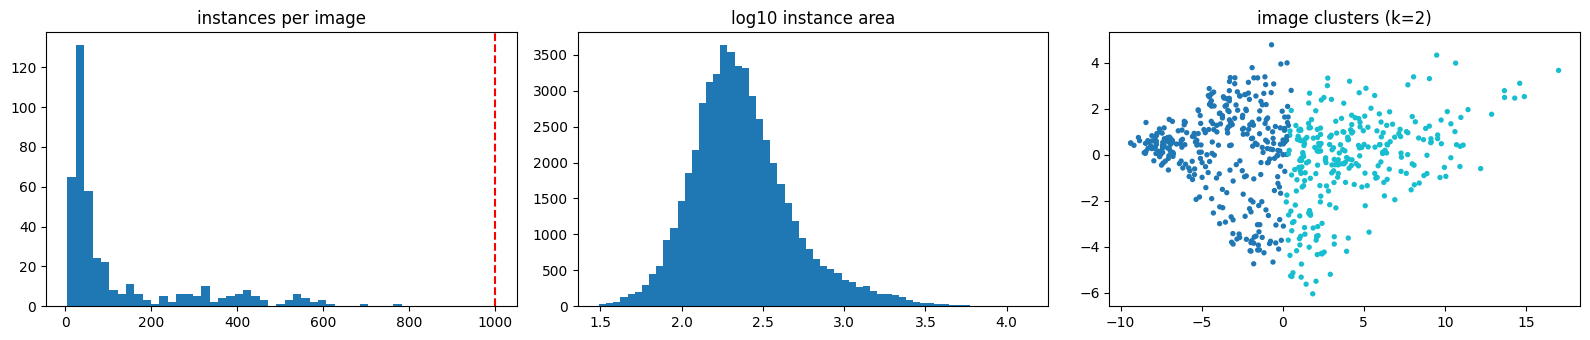

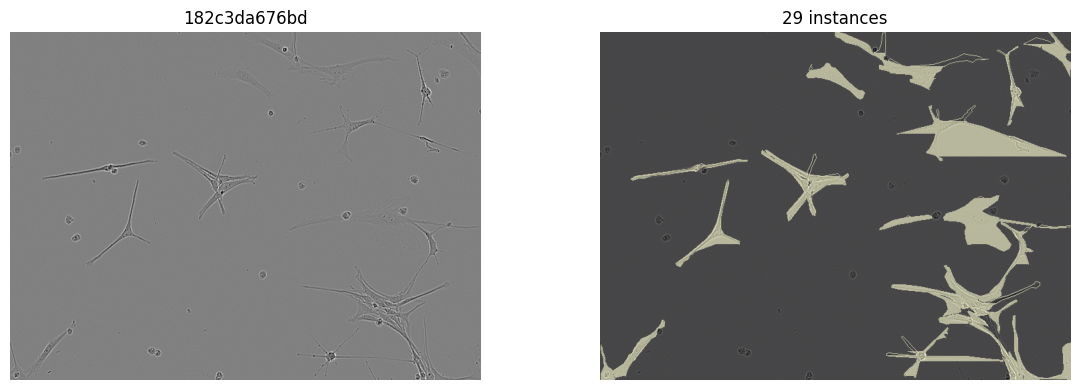

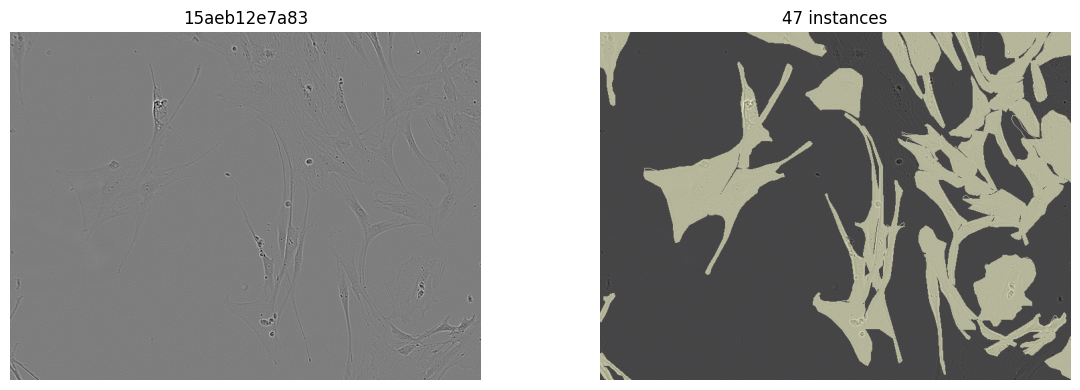

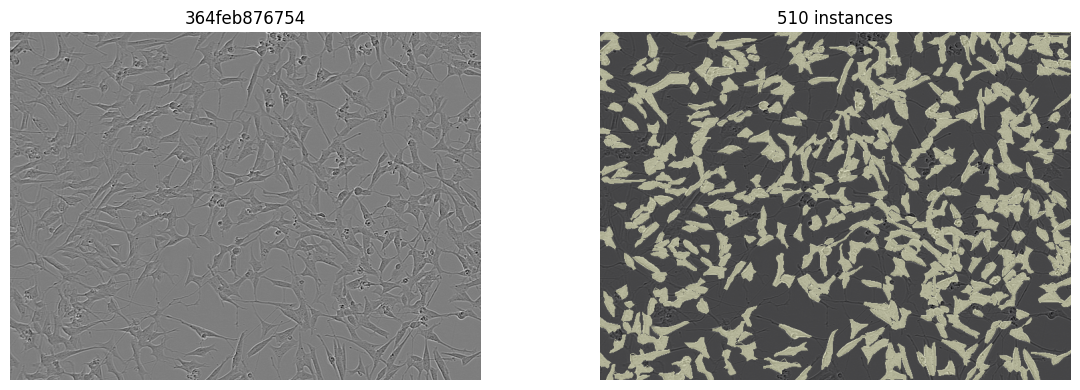

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
axes[0].hist(counts, bins=40)
axes[0].axvline(CFG.BOX_DET_PER_IMG, color="red", linestyle="--")
axes[0].set_title("instances per image")

axes[1].hist(np.log10(areas + 1), bins=60)
axes[1].set_title("log10 instance area")

axes[2].scatter(pca_features[:, 0], pca_features[:, 1], c=cluster_labels, s=8, cmap="tab10")
axes[2].set_title(f"image clusters (k={BEST_K})")

plt.tight_layout()
plt.savefig(ART / "eda_statistics.png", dpi=120)
plt.show()

def show_overlay(image_id):
    image = load_gray01(TRAIN_DIR / f"{image_id}.png")
    union = np.zeros((CFG.IMG_H, CFG.IMG_W), dtype=np.uint8)
    for flat in INST[image_id]:
        union.reshape(-1)[flat] = 1

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].imshow(image, cmap="gray")
    ax[0].set_title(image_id)
    ax[0].axis("off")
    ax[1].imshow(image, cmap="gray")
    ax[1].imshow(union, alpha=0.45, cmap="magma")
    ax[1].set_title(f"{len(INST[image_id])} instances")
    ax[1].axis("off")
    plt.tight_layout()
    plt.show()

sample_ids = [
    min(TRAIN_IDS, key=lambda image_id: abs(len(INST.get(image_id, [])) - np.percentile(counts, p)))
    for p in (25, 50, 95)
]
for sample_id in sample_ids:
    show_overlay(sample_id)


## 7 · Official instance-F1 metric

For each image:

1. compute pairwise mask Dice;
2. greedily select the current highest Dice pair;
3. accept it only when Dice ≥ 0.50;
4. remove the matched prediction and ground-truth mask;
5. calculate `2TP / (2TP + FP + FN)`.

The competition score is the plain mean across images.


In [13]:
from scipy.sparse import csr_matrix

NPIX = CFG.IMG_H * CFG.IMG_W

def sparse_masks(flats, npix):
    if len(flats) == 0:
        return csr_matrix((0, npix), dtype=np.float32)

    indptr = np.zeros(len(flats) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(flat) for flat in flats])
    indices = np.concatenate(flats).astype(np.int64)
    data = np.ones(indices.size, dtype=np.float32)
    return csr_matrix((data, indices, indptr), shape=(len(flats), npix))

def dice_matrix(gt_flats, pred_flats, npix):
    if len(gt_flats) == 0 or len(pred_flats) == 0:
        return np.zeros((len(gt_flats), len(pred_flats)), dtype=np.float32)

    gt_sparse = sparse_masks(gt_flats, npix)
    pred_sparse = sparse_masks(pred_flats, npix)
    intersection = (gt_sparse @ pred_sparse.T).toarray()

    gt_area = np.asarray(gt_sparse.sum(axis=1)).reshape(-1, 1)
    pred_area = np.asarray(pred_sparse.sum(axis=1)).reshape(1, -1)
    return (2.0 * intersection / np.maximum(gt_area + pred_area, 1.0)).astype(np.float32)

def greedy_match(dice, threshold=0.50):
    work = np.asarray(dice, dtype=np.float32).copy()
    if work.size == 0:
        return 0

    tp = 0
    while True:
        flat_index = int(np.argmax(work))
        best = float(work.flat[flat_index])
        if best < threshold:
            break
        gt_index, pred_index = np.unravel_index(flat_index, work.shape)
        tp += 1
        work[gt_index, :] = -1.0
        work[:, pred_index] = -1.0
    return tp

def instance_f1_from_dice(dice, threshold=0.50):
    n_gt, n_pred = dice.shape
    if n_gt == 0 and n_pred == 0:
        return 1.0
    if n_gt == 0 or n_pred == 0:
        return 0.0

    tp = greedy_match(dice, threshold)
    fp = n_pred - tp
    fn = n_gt - tp
    return 2.0 * tp / (2.0 * tp + fp + fn + 1e-8)

def score_dataset_f1(gt_by_id, pred_by_id, npix=NPIX, threshold=0.50, return_per_image=False):
    per_image = {}
    for image_id, gt_flats in gt_by_id.items():
        pred_flats = pred_by_id.get(image_id, [])
        dice = dice_matrix(gt_flats, pred_flats, npix)
        per_image[image_id] = instance_f1_from_dice(dice, threshold)

    mean_score = float(np.mean(list(per_image.values()))) if per_image else 0.0
    return (mean_score, per_image) if return_per_image else mean_score

# Unit tests, including the duplicate-prediction case.
_a = np.array([0, 1, 2], dtype=np.int32)
_b = np.array([10, 11], dtype=np.int32)
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a]}) - 1.0) < 1e-7
assert score_dataset_f1({"x": [_a]}, {"x": []}) == 0.0
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a, _a]}) - (2 / 3)) < 1e-7
assert abs(score_dataset_f1({"x": [_a, _b]}, {"x": [_a, _b]}) - 1.0) < 1e-7
print("official-metric unit tests: passed")


official-metric unit tests: passed


## 8 · Validation split, stratified by image cluster and density


## 8 · Near-duplicate grouping and a leakage-free validation split

Stage 2 scored **0.7909** on a random split and **0.4967** on the leaderboard. That 0.29 gap is far larger than sampling noise on 91 public images, and the usual cause in microscopy datasets is several images per field of view or time-lapse series ending up on both sides of a random split. This section measures that directly and splits by group instead.

In [14]:
# ---------------------------------------------------------------------------
# Near-duplicate grouping.  Stage 2 scored 0.7909 on a random 64-image split but
# 0.4967 on the leaderboard.  The most likely cause is that this dataset contains
# several images per field of view / time-lapse series, so a random split leaks
# almost-identical images into validation.  Group them first, then split by group.
# ---------------------------------------------------------------------------
from scipy.sparse import csr_matrix as _csr
from scipy.sparse.csgraph import connected_components

labeled_ids = [image_id for image_id in TRAIN_IDS if image_id in INST]

t0 = time.time()
thumbs = []
for image_id in labeled_ids:
    with Image.open(TRAIN_DIR / f"{image_id}.png") as im:
        a = np.asarray(im.convert("L").resize((88, 65), Image.BILINEAR), dtype=np.float32)
    a = a - a.mean()
    a = a / (np.linalg.norm(a) + 1e-6)
    thumbs.append(a.ravel())
THUMBS = np.stack(thumbs)
CORR = THUMBS @ THUMBS.T
np.fill_diagonal(CORR, 0.0)
print(f"thumbnail correlation matrix in {time.time() - t0:.0f}s")

off = CORR[np.triu_indices_from(CORR, k=1)]
print("pairwise correlation quantiles:",
      {f"p{p}": round(float(np.percentile(off, p)), 3) for p in (50, 90, 99, 99.9, 100)})

adjacency = _csr(CORR >= CFG.DUP_CORR_THR)
n_groups, group_of = connected_components(adjacency, directed=False)
GROUP = {image_id: int(g) for image_id, g in zip(labeled_ids, group_of)}

sizes = Counter(group_of.tolist())
size_hist = Counter(sizes.values())
print(f"\n>>> {n_groups} groups over {len(labeled_ids)} labelled images "
      f"(mean {len(labeled_ids)/max(n_groups,1):.2f} images/group)")
print("group-size histogram:", dict(sorted(size_hist.items())))
print("largest groups      :", [n for _, n in sizes.most_common(5)])

if n_groups >= 0.95 * len(labeled_ids):
    print("\n!! Almost every image is its own group at this threshold.")
    print("   Either the images really are independent, or DUP_CORR_THR is too high.")
    print("   Lower CFG.DUP_CORR_THR (try 0.55) if the val/leaderboard gap persists.")

STATS["n_groups"] = int(n_groups)
STATS["group_size_hist"] = {str(k): int(v) for k, v in sorted(size_hist.items())}
STATS["corr_quantiles"] = {f"p{p}": float(np.percentile(off, p)) for p in (50, 90, 99, 100)}


thumbnail correlation matrix in 3s
pairwise correlation quantiles: {'p50': -0.0, 'p90': 0.017, 'p99': 0.034, 'p99.9': 0.049, 'p100': 0.805}

>>> 421 groups over 424 labelled images (mean 1.01 images/group)
group-size histogram: {1: 418, 2: 3}
largest groups      : [2, 2, 2, 1, 1]

!! Almost every image is its own group at this threshold.
   Either the images really are independent, or DUP_CORR_THR is too high.
   Lower CFG.DUP_CORR_THR (try 0.55) if the val/leaderboard gap persists.


In [15]:
# ---------------------------------------------------------------------------
# Grouped, cluster- and density-stratified fold assignment.
# No group is ever split across the train/validation boundary.
# ---------------------------------------------------------------------------
group_members = defaultdict(list)
for image_id in labeled_ids:
    group_members[GROUP[image_id] if CFG.GROUP_SPLIT else image_id].append(image_id)

group_density = {
    g: float(np.mean([len(INST[i]) for i in members]))
    for g, members in group_members.items()
}
density_edges = np.percentile(list(group_density.values()), [33, 66])

def group_stratum(g):
    members = group_members[g]
    cluster = Counter(CLUSTER.get(i, -1) for i in members).most_common(1)[0][0]
    return f"{cluster}_{int(np.digitize(group_density[g], density_edges))}"

buckets = defaultdict(list)
for g in group_members:
    buckets[group_stratum(g)].append(g)

rng = np.random.RandomState(CFG.SEED)
fold_of_group = {}
counter = 0
for stratum in sorted(buckets):
    gs = sorted(buckets[stratum])
    rng.shuffle(gs)
    for g in gs:
        fold_of_group[g] = counter % CFG.N_FOLDS
        counter += 1

val_ids = sorted(i for g, members in group_members.items()
                 if fold_of_group[g] == CFG.FOLD for i in members)
train_ids = sorted(i for i in labeled_ids if i not in set(val_ids))

if CFG.SMOKE_TEST:
    train_ids = train_ids[:24]
    val_ids = val_ids[:12]

GT_VAL = {image_id: INST[image_id] for image_id in val_ids}
FOLD_OF_IMAGE = {i: fold_of_group[GROUP[i] if CFG.GROUP_SPLIT else i] for i in labeled_ids}

# leakage audit: highest correlation between any val image and any train image
index_of = {image_id: k for k, image_id in enumerate(labeled_ids)}
vi = [index_of[i] for i in val_ids]
ti = [index_of[i] for i in train_ids]
cross = CORR[np.ix_(vi, ti)] if vi and ti else np.zeros((1, 1))
print("grouped split :", CFG.GROUP_SPLIT, "| fold", CFG.FOLD, "of", CFG.N_FOLDS)
print("train images  :", len(train_ids))
print("val images    :", len(val_ids))
print("train inst/img:", round(float(np.mean([len(INST[x]) for x in train_ids])), 1))
print("val   inst/img:", round(float(np.mean([len(INST[x]) for x in val_ids])), 1))
print("val cluster mix:", dict(Counter(CLUSTER.get(i, -1) for i in val_ids)))
print(f"max val-to-train correlation: {float(cross.max()):.3f} "
      f"(>= {CFG.DUP_CORR_THR} would mean the split still leaks)")
print(f"mean of per-val-image max correlation to train: {float(cross.max(axis=1).mean()):.3f}")

STATS["train_ids"] = train_ids
STATS["val_ids"] = val_ids
STATS["fold"] = int(CFG.FOLD)
STATS["max_val_train_corr"] = float(cross.max())
STATS["mean_val_train_corr"] = float(cross.max(axis=1).mean())


grouped split : True | fold 0 of 5
train images  : 338
val images    : 86
train inst/img: 122.3
val   inst/img: 136.2
val cluster mix: {1: 41, 0: 45}
max val-to-train correlation: 0.665 (>= 0.72 would mean the split still leaks)
mean of per-val-image max correlation to train: 0.076


## 9 · Dataset, augmentation, and data loaders


In [16]:
from torch.utils.data import Dataset, DataLoader

class CellDataset(Dataset):
    def __init__(self, ids, image_dir, training):
        self.ids = list(ids)
        self.image_dir = Path(image_dir)
        self.training = bool(training)

    def __len__(self):
        return len(self.ids)

    def augment(self, image, masks):
        if random.random() < CFG.AUG_HFLIP:
            image = image[:, ::-1]
            masks = masks[:, :, ::-1]

        if random.random() < CFG.AUG_VFLIP:
            image = image[::-1, :]
            masks = masks[:, ::-1, :]

        if random.random() < CFG.AUG_ROT90:
            k = random.choice((1, 2, 3))
            image = np.rot90(image, k)
            masks = np.rot90(masks, k, axes=(1, 2))

        image = np.ascontiguousarray(image)
        masks = np.ascontiguousarray(masks)

        if random.random() < CFG.AUG_BRIGHTNESS_CONTRAST:
            contrast = random.uniform(0.85, 1.18)
            brightness = random.uniform(-0.10, 0.10)
            image = np.clip((image - 0.5) * contrast + 0.5 + brightness, 0, 1)

        if random.random() < CFG.AUG_GAMMA:
            image = np.clip(image, 1e-4, 1.0) ** random.uniform(0.75, 1.35)

        if random.random() < CFG.AUG_NOISE:
            sigma = random.uniform(0.005, 0.02)
            image = np.clip(image + np.random.normal(0, sigma, image.shape), 0, 1)

        return image.astype(np.float32), masks

    def __getitem__(self, index):
        image_id = self.ids[index]
        image = load_gray01(self.image_dir / f"{image_id}.png")

        flats = INST[image_id]
        if CFG.MAX_INSTANCES_TRAIN and len(flats) > CFG.MAX_INSTANCES_TRAIN:
            chosen = np.random.choice(len(flats), CFG.MAX_INSTANCES_TRAIN, replace=False)
            flats = [flats[j] for j in chosen]

        masks = np.zeros(
            (len(flats), CFG.IMG_H * CFG.IMG_W),
            dtype=np.uint8,
        )
        for mask_index, flat in enumerate(flats):
            masks[mask_index, flat] = 1
        masks = masks.reshape(len(flats), CFG.IMG_H, CFG.IMG_W)

        if self.training:
            image, masks = self.augment(image, masks)

        height, width = image.shape
        boxes = []
        kept_masks = []

        for mask in masks:
            ys, xs = np.nonzero(mask)
            if ys.size < CFG.MIN_GT_AREA:
                continue
            x0, x1 = xs.min(), xs.max()
            y0, y1 = ys.min(), ys.max()
            if x1 <= x0 or y1 <= y0:
                continue
            boxes.append([x0, y0, x1 + 1, y1 + 1])
            kept_masks.append(mask)

        if kept_masks:
            masks_array = np.stack(kept_masks).astype(np.uint8)
        else:
            masks_array = np.zeros((0, height, width), dtype=np.uint8)

        target = {
            "boxes": torch.as_tensor(np.asarray(boxes, dtype=np.float32).reshape(-1, 4)),
            "labels": torch.ones(len(boxes), dtype=torch.int64),
            "masks": torch.as_tensor(masks_array, dtype=torch.uint8),
            "image_id": torch.tensor([index], dtype=torch.int64),
        }

        tensor = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).repeat(3, 1, 1)
        return tensor, target, image_id

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    CellDataset(train_ids, TRAIN_DIR, training=True),
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,
    num_workers=CFG.NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
    prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
    drop_last=True,
)

val_loader = DataLoader(
    CellDataset(val_ids, TRAIN_DIR, training=False),
    batch_size=1,
    shuffle=False,
    num_workers=CFG.NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
    persistent_workers=False,
)

batch_images, batch_targets, batch_ids = next(iter(train_loader))
print("batch image shapes:", [tuple(image.shape) for image in batch_images])
print("instances:", [len(target["labels"]) for target in batch_targets])
print(
    "mask target memory:",
    f"{sum(target['masks'].numel() for target in batch_targets) / 1e6:.0f} MB uint8",
)


batch image shapes: [(3, 520, 704)]
instances: [25]
mask target memory: 9 MB uint8


## 10 · Mask R-CNN v2 with Dice-aligned mask loss and corrected anchors


In [17]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection import roi_heads as roi_heads_module

ORIGINAL_MASK_LOSS = roi_heads_module.maskrcnn_loss

def maskrcnn_loss_bce_dice(mask_logits, proposals, gt_masks, gt_labels, mask_matched_idxs):
    resolution = mask_logits.shape[-1]

    if sum(int(matched.numel()) for matched in mask_matched_idxs) == 0:
        return mask_logits.sum() * 0.0

    labels = torch.cat(
        [labels_per_image[matched] for labels_per_image, matched in zip(gt_labels, mask_matched_idxs)],
        dim=0,
    )
    targets = torch.cat(
        [
            roi_heads_module.project_masks_on_boxes(masks, proposals_per_image, matched, resolution)
            for masks, proposals_per_image, matched in zip(gt_masks, proposals, mask_matched_idxs)
        ],
        dim=0,
    )

    if targets.numel() == 0:
        return mask_logits.sum() * 0.0

    row_index = torch.arange(labels.shape[0], device=labels.device)
    logits = mask_logits[row_index, labels].float()
    targets = targets.float()

    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(1, 2))
    denominator = probabilities.sum(dim=(1, 2)) + targets.sum(dim=(1, 2))
    dice_loss = 1.0 - (2.0 * intersection + 1.0) / (denominator + 1.0)

    return CFG.BCE_W * bce + CFG.DICE_W * dice_loss.mean()

roi_heads_module.maskrcnn_loss = (
    maskrcnn_loss_bce_dice if CFG.MASK_LOSS == "bce+dice" else ORIGINAL_MASK_LOSS
)

def build_model():
    common = {
        "box_detections_per_img": CFG.BOX_DET_PER_IMG,
        "min_size": min(CFG.MIN_SIZE_TRAIN),
        "max_size": CFG.MAX_SIZE,
        "rpn_batch_size_per_image": CFG.RPN_BATCH_PER_IMG,
        "box_batch_size_per_image": CFG.BOX_BATCH_PER_IMG,
    }

    if CFG.ARCH == "v2":
        from torchvision.models.detection import (
            maskrcnn_resnet50_fpn_v2,
            MaskRCNN_ResNet50_FPN_V2_Weights,
        )
        constructor = maskrcnn_resnet50_fpn_v2
        coco_weights = MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
    else:
        from torchvision.models.detection import (
            maskrcnn_resnet50_fpn,
            MaskRCNN_ResNet50_FPN_Weights,
        )
        constructor = maskrcnn_resnet50_fpn
        coco_weights = MaskRCNN_ResNet50_FPN_Weights.COCO_V1

    from torchvision.models import ResNet50_Weights

    if CFG.WEIGHTS_MODE == "coco":
        model = constructor(
            weights=coco_weights,
            trainable_backbone_layers=CFG.TRAINABLE_BACKBONE_LAYERS,
            **common,
        )
        weight_description = "COCO detector"
    elif CFG.WEIGHTS_MODE == "imagenet_bb":
        model = constructor(
            weights=None,
            weights_backbone=ResNet50_Weights.IMAGENET1K_V1,
            trainable_backbone_layers=CFG.TRAINABLE_BACKBONE_LAYERS,
            **common,
        )
        weight_description = "ImageNet backbone only"
    else:
        raise ValueError(f"Unknown WEIGHTS_MODE: {CFG.WEIGHTS_MODE}")

    box_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(box_features, 2)

    mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_features, 256, 2)

    ratios = tuple(CFG.ASPECT_RATIOS)
    model.rpn.anchor_generator = AnchorGenerator(
        sizes=tuple(CFG.ANCHOR_SIZES),
        aspect_ratios=tuple(ratios for _ in CFG.ANCHOR_SIZES),
    )

    model.roi_heads.nms_thresh = CFG.BOX_NMS_THR
    model.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    model.transform.max_size = CFG.MAX_SIZE

    if CFG.NORMALIZE_WITH_DATASET_STATS:
        model.transform.image_mean = [DS_MEAN] * 3
        model.transform.image_std = [DS_STD] * 3

    print("weights       :", weight_description)
    print("mask loss     :", CFG.MASK_LOSS)
    print("anchors       :", model.rpn.anchor_generator.sizes)
    print("ratios        :", model.rpn.anchor_generator.aspect_ratios[0])
    print("normalization :", model.transform.image_mean, model.transform.image_std)
    print("box NMS       :", model.roi_heads.nms_thresh)
    print("detections/img:", model.roi_heads.detections_per_img)
    return model

model = build_model().to(DEVICE)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"trainable parameters: {trainable_parameters / 1e6:.1f}M")


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 181MB/s]  


weights       : COCO detector
mask loss     : bce+dice
anchors       : ((20,), (24,), (32,), (44,), (96,))
ratios        : (0.62, 1.0, 1.58)
normalization : [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
box NMS       : 0.6
detections/img: 1000
trainable parameters: 45.9M


## 11 · Inference helpers, cached cropped masks, and checkpoint evaluation


In [18]:
def autocast_context():
    try:
        return torch.amp.autocast("cuda", enabled=CFG.AMP)
    except Exception:
        return torch.cuda.amp.autocast(enabled=CFG.AMP)

def set_inference_config(model, score_threshold, max_detections):
    model.roi_heads.score_thresh = float(score_threshold)
    model.roi_heads.detections_per_img = int(max_detections)
    model.roi_heads.nms_thresh = float(CFG.BOX_NMS_THR)
    model.rpn._pre_nms_top_n["testing"] = int(CFG.RPN_PRE_TEST)
    model.rpn._post_nms_top_n["testing"] = int(CFG.RPN_POST_TEST)
    model.transform.min_size = (CFG.MIN_SIZE_TEST,)

@torch.no_grad()
def cache_predictions(model, ids, image_dir, progress_every=25):
    model.eval()
    set_inference_config(model, CFG.CACHE_SCORE_THR, CFG.CACHE_MAX_DET)
    image_dir = Path(image_dir)
    cache = {}

    for position, image_id in enumerate(ids, 1):
        image = load_gray01(image_dir / f"{image_id}.png")
        tensor = (
            torch.from_numpy(np.ascontiguousarray(image))
            .unsqueeze(0)
            .repeat(3, 1, 1)
            .to(DEVICE, non_blocking=True)
        )

        try:
            with autocast_context():
                output = model([tensor])[0]
        except RuntimeError as error:
            if "out of memory" not in str(error).lower():
                raise
            print(f"OOM on {image_id}; retrying after clearing cache")
            del tensor
            gc.collect()
            torch.cuda.empty_cache()
            image = load_gray01(image_dir / f"{image_id}.png")
            tensor = torch.from_numpy(image).unsqueeze(0).repeat(3, 1, 1).to(DEVICE)
            with autocast_context():
                output = model([tensor])[0]

        scores = output["scores"].detach().float().cpu().numpy()
        boxes = output["boxes"].detach().float().cpu().numpy()

        # Convert on GPU before transfer: 4x less host traffic than float32.
        masks_u8 = (
            output["masks"][:, 0]
            .detach()
            .clamp_(0, 1)
            .mul_(255)
            .to(torch.uint8)
            .cpu()
            .numpy()
        )

        entries = []
        for score, box, mask_u8 in zip(scores, boxes, masks_u8):
            x0, y0, x1, y1 = box
            x0 = max(0, int(math.floor(x0)) - 2)
            y0 = max(0, int(math.floor(y0)) - 2)
            x1 = min(CFG.IMG_W, int(math.ceil(x1)) + 2)
            y1 = min(CFG.IMG_H, int(math.ceil(y1)) + 2)
            if x1 <= x0 or y1 <= y0:
                continue

            crop = np.ascontiguousarray(mask_u8[y0:y1, x0:x1])
            if crop.size == 0 or crop.max() == 0:
                continue
            entries.append((float(score), y0, x0, crop))

        entries.sort(key=lambda item: -item[0])
        cache[image_id] = entries

        del output, masks_u8, tensor
        if position % progress_every == 0 or position == len(ids):
            print(f"  cached {position}/{len(ids)}", flush=True)

    return cache

def build_instances(entries, mask_threshold, min_area, height, width, allow_overlap):
    occupied = np.zeros(height * width, dtype=bool) if not allow_overlap else None
    instances = []

    for score, y0, x0, crop in entries:
        binary = crop > int(round(mask_threshold * 255))
        ys, xs = np.nonzero(binary)
        if ys.size == 0:
            continue

        flat = (ys + y0).astype(np.int64) * width + (xs + x0)
        if occupied is not None:
            flat = flat[~occupied[flat]]

        if flat.size < min_area:
            continue

        if occupied is not None:
            occupied[flat] = True

        instances.append((float(score), flat.astype(np.int32)))

    return instances

def evaluate_cached_predictions(
    cache,
    ids,
    gt_by_id,
    mask_threshold,
    min_area,
    allow_overlap,
    score_grid,
):
    built = {
        image_id: build_instances(
            cache[image_id],
            mask_threshold,
            min_area,
            CFG.IMG_H,
            CFG.IMG_W,
            allow_overlap,
        )
        for image_id in ids
    }

    matrices = {}
    for image_id in ids:
        pred_flats = [flat for _, flat in built[image_id]]
        scores = np.asarray([score for score, _ in built[image_id]], dtype=np.float32)
        matrices[image_id] = (
            dice_matrix(gt_by_id[image_id], pred_flats, NPIX),
            scores,
        )

    rows = []
    for score_threshold in score_grid:
        per_image = {}
        predictions = []

        for image_id in ids:
            dice, scores = matrices[image_id]
            n_keep = int((scores >= score_threshold).sum())
            score = instance_f1_from_dice(
                dice[:, :n_keep],
                CFG.DICE_MATCH_THR,
            )
            per_image[image_id] = score
            predictions.append(n_keep)

        rows.append(
            {
                "score_thr": float(score_threshold),
                "f1": float(np.mean(list(per_image.values()))),
                "mean_predictions": float(np.mean(predictions)),
                "per_image": per_image,
            }
        )

    return rows, built, matrices

@torch.no_grad()
def quick_evaluate_checkpoint(model):
    cache = cache_predictions(model, val_ids, TRAIN_DIR, progress_every=max(len(val_ids), 1))
    results, _, _ = evaluate_cached_predictions(
        cache=cache,
        ids=val_ids,
        gt_by_id=GT_VAL,
        mask_threshold=CFG.EVAL_MASK_THR,
        min_area=CFG.EVAL_MIN_AREA,
        allow_overlap=False,
        score_grid=CFG.EVAL_SCORE_GRID,
    )
    best = max(results, key=lambda row: row["f1"])
    del cache
    gc.collect()
    torch.cuda.empty_cache()
    return best


## 12 · Optimizer, AMP scaler, cosine schedule, and resume state


In [31]:
backbone_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if parameter.requires_grad and name.startswith("backbone")
]
head_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if parameter.requires_grad and not name.startswith("backbone")
]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": CFG.LR * CFG.BACKBONE_LR_MULT},
        {"params": head_parameters, "lr": CFG.LR},
    ],
    weight_decay=CFG.WEIGHT_DECAY,
)

optimizer_steps_per_epoch = max(1, math.ceil(len(train_loader) / CFG.ACCUM_STEPS))
total_optimizer_steps = optimizer_steps_per_epoch * CFG.EPOCHS

def learning_rate_multiplier(step):
    if step < CFG.WARMUP_STEPS:
        return (step + 1) / max(CFG.WARMUP_STEPS, 1)
    progress = (step - CFG.WARMUP_STEPS) / max(
        total_optimizer_steps - CFG.WARMUP_STEPS,
        1,
    )
    progress = min(max(progress, 0.0), 1.0)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, learning_rate_multiplier)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.AMP)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.AMP)

BEST_PATH = CKPT / "best.pt"
LAST_PATH = CKPT / "last.pt"

start_epoch = 1
best_score = -1.0
training_log = []

if LAST_PATH.exists():
    checkpoint = torch.load(LAST_PATH, map_location="cpu")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    start_epoch = int(checkpoint["epoch"]) + 1
    best_score = float(checkpoint["best_score"])
    training_log = checkpoint.get("training_log", [])
    print(f"resumed from epoch {checkpoint['epoch']} with best F1={best_score:.4f}")
else:
    print("starting a fresh run")

print("optimizer steps/epoch:", optimizer_steps_per_epoch)
print("total optimizer steps:", total_optimizer_steps)
print("warmup steps:", CFG.WARMUP_STEPS)


resumed from epoch 40 with best F1=0.7314
optimizer steps/epoch: 85
total optimizer steps: 3400
warmup steps: 300


## 13 · Full training with mixed precision and wall-clock protection


In [ ]:
epoch_durations = []

for epoch in range(start_epoch, CFG.EPOCHS + 1):
    estimated_next_epoch = float(np.mean(epoch_durations[-3:])) if epoch_durations else 0.0
    remaining_budget = CFG.TOTAL_BUDGET_SEC - elapsed_seconds()

    if epoch_durations and remaining_budget < estimated_next_epoch + CFG.RESERVE_SEC:
        print(
            f"Stopping before epoch {epoch}: remaining {format_duration(remaining_budget)}, "
            f"estimated epoch {format_duration(estimated_next_epoch)}, "
            f"reserve {format_duration(CFG.RESERVE_SEC)}"
        )
        break

    model.train()
    model.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    epoch_start = time.time()
    accumulated = defaultdict(float)
    valid_iterations = 0

    optimizer.zero_grad(set_to_none=True)

    for iteration, (images, targets, _) in enumerate(train_loader, 1):
        images = [image.to(DEVICE, non_blocking=True) for image in images]
        targets = [
            {
                key: value.to(DEVICE, non_blocking=True) if torch.is_tensor(value) else value
                for key, value in target.items()
            }
            for target in targets
        ]

        if any(target["boxes"].shape[0] == 0 for target in targets):
            continue

        with autocast_context():
            loss_dict = model(images, targets)
            total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss):
            print(f"  non-finite loss at iteration {iteration}; skipped")
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(total_loss / CFG.ACCUM_STEPS).backward()
        valid_iterations += 1

        for name, value in loss_dict.items():
            accumulated[name] += float(value.detach())
        accumulated["total"] += float(total_loss.detach())

        should_step = (
            iteration % CFG.ACCUM_STEPS == 0
            or iteration == len(train_loader)
        )
        if should_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        if iteration % 50 == 0:
            denom = max(valid_iterations, 1)
            print(
                f"  epoch {epoch:02d} iter {iteration:03d}/{len(train_loader)} "
                f"loss={accumulated['total'] / denom:.4f} "
                f"mask={accumulated['loss_mask'] / denom:.4f} "
                f"lr={scheduler.get_last_lr()[-1]:.2e} "
                f"{(time.time() - epoch_start) / iteration:.2f}s/iter",
                flush=True,
            )

    epoch_seconds = time.time() - epoch_start
    epoch_durations.append(epoch_seconds)
    denom = max(valid_iterations, 1)

    row = {
        "epoch": epoch,
        **{name: value / denom for name, value in accumulated.items()},
        "lr": scheduler.get_last_lr()[-1],
        "train_seconds": round(epoch_seconds, 1),
    }

    evaluate_now = (
        epoch >= CFG.EVAL_START_EPOCH
        and (
            epoch >= CFG.EVAL_DENSE_FROM
            or epoch % CFG.EVAL_EVERY_EARLY == 0
        )
    )

    if evaluate_now:
        evaluation_start = time.time()
        evaluation = quick_evaluate_checkpoint(model)
        row["val_f1"] = evaluation["f1"]
        row["val_score_thr"] = evaluation["score_thr"]
        row["val_mean_predictions"] = evaluation["mean_predictions"]
        row["eval_seconds"] = round(time.time() - evaluation_start, 1)

        if evaluation["f1"] > best_score:
            best_score = float(evaluation["f1"])
            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "score": best_score,
                    "score_threshold": evaluation["score_thr"],
                    "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()},
                },
                BEST_PATH,
            )
            row["saved_best"] = True

    training_log.append(row)

    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "epoch": epoch,
            "best_score": best_score,
            "training_log": training_log,
        },
        LAST_PATH,
    )
    pd.DataFrame(training_log).to_csv(ART / "training_log.csv", index=False)

    print(
        f"[epoch {epoch:02d}] "
        + " ".join(
            f"{key}={value:.4f}" if isinstance(value, float) else f"{key}={value}"
            for key, value in row.items()
        ),
        flush=True,
    )

    gc.collect()
    torch.cuda.empty_cache()

# If the time guard stopped before the first scheduled evaluation, preserve the latest model.
if not BEST_PATH.exists():
    print("No evaluated best checkpoint exists; saving the current model as best.pt")
    torch.save(
        {
            "model": model.state_dict(),
            "epoch": training_log[-1]["epoch"] if training_log else 0,
            "score": best_score,
            "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()},
        },
        BEST_PATH,
    )

print("\nbest validation F1:", best_score)
print("elapsed:", format_duration(elapsed_seconds()))
print(pd.DataFrame(training_log).tail(10).to_string(index=False))
STATS["best_val_score_during_training"] = float(best_score)


  epoch 01 iter 050/338 loss=4.1268 mask=1.6427 lr=6.50e-06 3.75s/iter
  epoch 01 iter 100/338 loss=3.6661 mask=1.5252 lr=1.30e-05 2.31s/iter
  epoch 01 iter 150/338 loss=3.2470 mask=1.3320 lr=1.90e-05 1.70s/iter
  epoch 01 iter 200/338 loss=3.0640 mask=1.2333 lr=2.55e-05 1.40s/iter
  epoch 01 iter 250/338 loss=2.8565 mask=1.1495 lr=3.15e-05 1.25s/iter
  epoch 01 iter 300/338 loss=2.7184 mask=1.0898 lr=3.80e-05 1.11s/iter
[epoch 01] epoch=1 loss_classifier=0.3960 loss_box_reg=0.2504 loss_mask=1.0433 loss_objectness=0.7991 loss_rpn_box_reg=0.1402 total=2.6289 lr=0.0000 train_seconds=348.0000
  epoch 02 iter 050/338 loss=1.6705 mask=0.5787 lr=4.90e-05 0.38s/iter
  epoch 02 iter 100/338 loss=1.6769 mask=0.6018 lr=5.55e-05 0.35s/iter
  epoch 02 iter 150/338 loss=1.6373 mask=0.5841 lr=6.15e-05 0.37s/iter
  epoch 02 iter 200/338 loss=1.6167 mask=0.5790 lr=6.80e-05 0.36s/iter
  epoch 02 iter 250/338 loss=1.5948 mask=0.5750 lr=7.40e-05 0.34s/iter
  epoch 02 iter 300/338 loss=1.5857 mask=0.5722

In [30]:
print(type(model), len(train_ids))

<class 'torchvision.models.detection.mask_rcnn.MaskRCNN'> 338


## 14 · Load the best checkpoint and cache validation predictions once


In [33]:
best_checkpoint = torch.load(BEST_PATH, map_location="cpu")
model.load_state_dict(best_checkpoint["model"])
model.to(DEVICE).eval()
print(
    "loaded best checkpoint:",
    "epoch", best_checkpoint.get("epoch"),
    "score", best_checkpoint.get("score"),
)

validation_cache_start = time.time()
VAL_CACHE = cache_predictions(model, val_ids, TRAIN_DIR)
print(
    f"validation cache completed in {format_duration(time.time() - validation_cache_start)}; "
    f"mean raw detections/image={np.mean([len(v) for v in VAL_CACHE.values()]):.1f}"
)


loaded best checkpoint: epoch 24 score 0.7313824256247006
  cached 25/86
  cached 50/86
  cached 75/86
  cached 86/86
validation cache completed in 0h 01m; mean raw detections/image=642.2


## 15 · Full F1 post-processing sweep, including overlap handling


In [34]:
summary_rows = []
per_image_rows = []

for mask_threshold in CFG.SWEEP_MASK_THR:
    for min_area in MIN_AREA_GRID:
        for allow_overlap in CFG.SWEEP_ALLOW_OVERLAP:
            results, _, _ = evaluate_cached_predictions(
                cache=VAL_CACHE,
                ids=val_ids,
                gt_by_id=GT_VAL,
                mask_threshold=mask_threshold,
                min_area=min_area,
                allow_overlap=allow_overlap,
                score_grid=CFG.SWEEP_SCORE_THR,
            )

            for result in results:
                summary_rows.append(
                    {
                        "mask_thr": float(mask_threshold),
                        "min_area": int(min_area),
                        "allow_overlap": bool(allow_overlap),
                        "score_thr": float(result["score_thr"]),
                        "f1": float(result["f1"]),
                        "mean_predictions": float(result["mean_predictions"]),
                    }
                )

                for image_id, image_f1 in result["per_image"].items():
                    per_image_rows.append(
                        {
                            "id": image_id,
                            "cluster": int(CLUSTER.get(image_id, -1)),
                            "mask_thr": float(mask_threshold),
                            "min_area": int(min_area),
                            "allow_overlap": bool(allow_overlap),
                            "score_thr": float(result["score_thr"]),
                            "f1": float(image_f1),
                        }
                    )

sweep = pd.DataFrame(summary_rows).sort_values("f1", ascending=False).reset_index(drop=True)
per_image_sweep = pd.DataFrame(per_image_rows)

sweep.to_csv(ART / "sweep_results.csv", index=False)
per_image_sweep.to_csv(ART / "sweep_per_image.csv", index=False)

print(sweep.head(15).to_string(index=False))

best_global_row = sweep.iloc[0]

# Plateau-centre selection.  The argmax of a 49-point score-threshold curve measured on
# ~70 images is partly noise; the centre of the near-optimal plateau transfers better.
if CFG.ROBUST_THRESHOLD:
    same_shape = sweep[
        np.isclose(sweep["mask_thr"], best_global_row.mask_thr)
        & (sweep["min_area"] == best_global_row.min_area)
        & (sweep["allow_overlap"] == best_global_row.allow_overlap)
    ].sort_values("score_thr")
    plateau = same_shape[same_shape["f1"] >= best_global_row.f1 - CFG.ROBUST_TOL]
    chosen_score_thr = float(np.median(plateau["score_thr"].to_numpy()))
    # snap to the nearest grid point that was actually measured
    grid = same_shape["score_thr"].to_numpy()
    chosen_score_thr = float(grid[np.argmin(np.abs(grid - chosen_score_thr))])
    print(f"plateau within {CFG.ROBUST_TOL} of the max spans "
          f"score_thr {plateau['score_thr'].min():.2f}-{plateau['score_thr'].max():.2f}; "
          f"argmax={best_global_row.score_thr:.2f} -> using {chosen_score_thr:.2f}")
else:
    chosen_score_thr = float(best_global_row.score_thr)

GLOBAL_POST = {
    "mask_thr": float(best_global_row.mask_thr),
    "min_area": int(best_global_row.min_area),
    "allow_overlap": bool(best_global_row.allow_overlap),
    "score_thr": chosen_score_thr,
}
_sel = sweep[
    np.isclose(sweep["mask_thr"], GLOBAL_POST["mask_thr"])
    & (sweep["min_area"] == GLOBAL_POST["min_area"])
    & (sweep["allow_overlap"] == GLOBAL_POST["allow_overlap"])
    & np.isclose(sweep["score_thr"], GLOBAL_POST["score_thr"])
]
GLOBAL_F1 = float(_sel["f1"].iloc[0]) if len(_sel) else float(best_global_row.f1)
print("argmax F1 :", float(best_global_row.f1))

print("\nglobal post-processing:", GLOBAL_POST)
print("global validation F1:", GLOBAL_F1)


 mask_thr  min_area  allow_overlap  score_thr       f1  mean_predictions
      0.6       103          False       0.24 0.751644        111.348837
      0.6       103          False       0.28 0.751015        106.476744
      0.6       103          False       0.26 0.750732        108.941860
      0.5       103          False       0.28 0.750624        107.453488
      0.5       103          False       0.24 0.750553        112.581395
      0.5       103          False       0.30 0.750066        104.953488
      0.5       103          False       0.26 0.750007        110.058140
      0.5       103          False       0.32 0.749888        102.383721
      0.6       103          False       0.30 0.749831        104.127907
      0.6       103          False       0.32 0.749189        101.627907
      0.6       103          False       0.22 0.748762        114.186047
      0.5       103          False       0.34 0.748226        100.104651
      0.6        87          False       0.28 0.747

In [35]:
# Cluster-specific thresholds reuse the already-computed per-image sweep.
cluster_posts = {}
cluster_best_rows = []

parameter_columns = ["mask_thr", "min_area", "allow_overlap", "score_thr"]

for cluster_id in sorted(per_image_sweep["cluster"].unique()):
    cluster_image_ids = [
        image_id for image_id in val_ids
        if CLUSTER.get(image_id, -1) == cluster_id
    ]
    if len(cluster_image_ids) < CFG.PER_CLUSTER_MIN_VAL:
        continue

    cluster_scores = (
        per_image_sweep[per_image_sweep["cluster"] == cluster_id]
        .groupby(parameter_columns, as_index=False)["f1"]
        .mean()
        .sort_values("f1", ascending=False)
    )
    best = cluster_scores.iloc[0]
    post = {
        "mask_thr": float(best.mask_thr),
        "min_area": int(best.min_area),
        "allow_overlap": bool(best.allow_overlap),
        "score_thr": float(best.score_thr),
    }
    cluster_posts[int(cluster_id)] = post
    cluster_best_rows.append(
        {
            "cluster": int(cluster_id),
            "n_val": len(cluster_image_ids),
            "f1": float(best.f1),
            **post,
        }
    )

if cluster_best_rows:
    print(pd.DataFrame(cluster_best_rows).to_string(index=False))
else:
    print("No cluster had enough validation images for separate thresholds.")

selected_cluster_scores = []
for image_id in val_ids:
    cluster_id = int(CLUSTER.get(image_id, -1))
    post = cluster_posts.get(cluster_id, GLOBAL_POST)

    mask = (
        (per_image_sweep["id"] == image_id)
        & np.isclose(per_image_sweep["mask_thr"], post["mask_thr"])
        & (per_image_sweep["min_area"] == post["min_area"])
        & (per_image_sweep["allow_overlap"] == post["allow_overlap"])
        & np.isclose(per_image_sweep["score_thr"], post["score_thr"])
    )
    matches = per_image_sweep.loc[mask, "f1"]
    if len(matches):
        selected_cluster_scores.append(float(matches.iloc[0]))

CLUSTER_F1 = (
    float(np.mean(selected_cluster_scores))
    if len(selected_cluster_scores) == len(val_ids)
    else float("-inf")
)
cluster_gain = CLUSTER_F1 - GLOBAL_F1

USE_CLUSTER_POST = (
    CFG.PER_CLUSTER_THRESHOLDS is True
    or (
        CFG.PER_CLUSTER_THRESHOLDS == "auto"
        and cluster_posts
        and cluster_gain >= CFG.PER_CLUSTER_MIN_GAIN
    )
)

print("\nglobal F1 :", GLOBAL_F1)
print("cluster F1:", CLUSTER_F1)
print("gain       :", cluster_gain)
print("use cluster thresholds:", USE_CLUSTER_POST)

STATS["global_post"] = GLOBAL_POST
STATS["global_f1"] = GLOBAL_F1
STATS["cluster_posts"] = {str(k): v for k, v in cluster_posts.items()}
STATS["cluster_f1"] = CLUSTER_F1
STATS["use_cluster_post"] = bool(USE_CLUSTER_POST)


 cluster  n_val       f1  mask_thr  min_area  allow_overlap  score_thr
       0     45 0.694802       0.5       103          False       0.28
       1     41 0.814886       0.6       103          False       0.32

global F1 : 0.7507317854202163
cluster F1: 0.7520512883576381
gain       : 0.0013195029374217793
use cluster thresholds: False


## 16 · Prediction visualizations on validation images


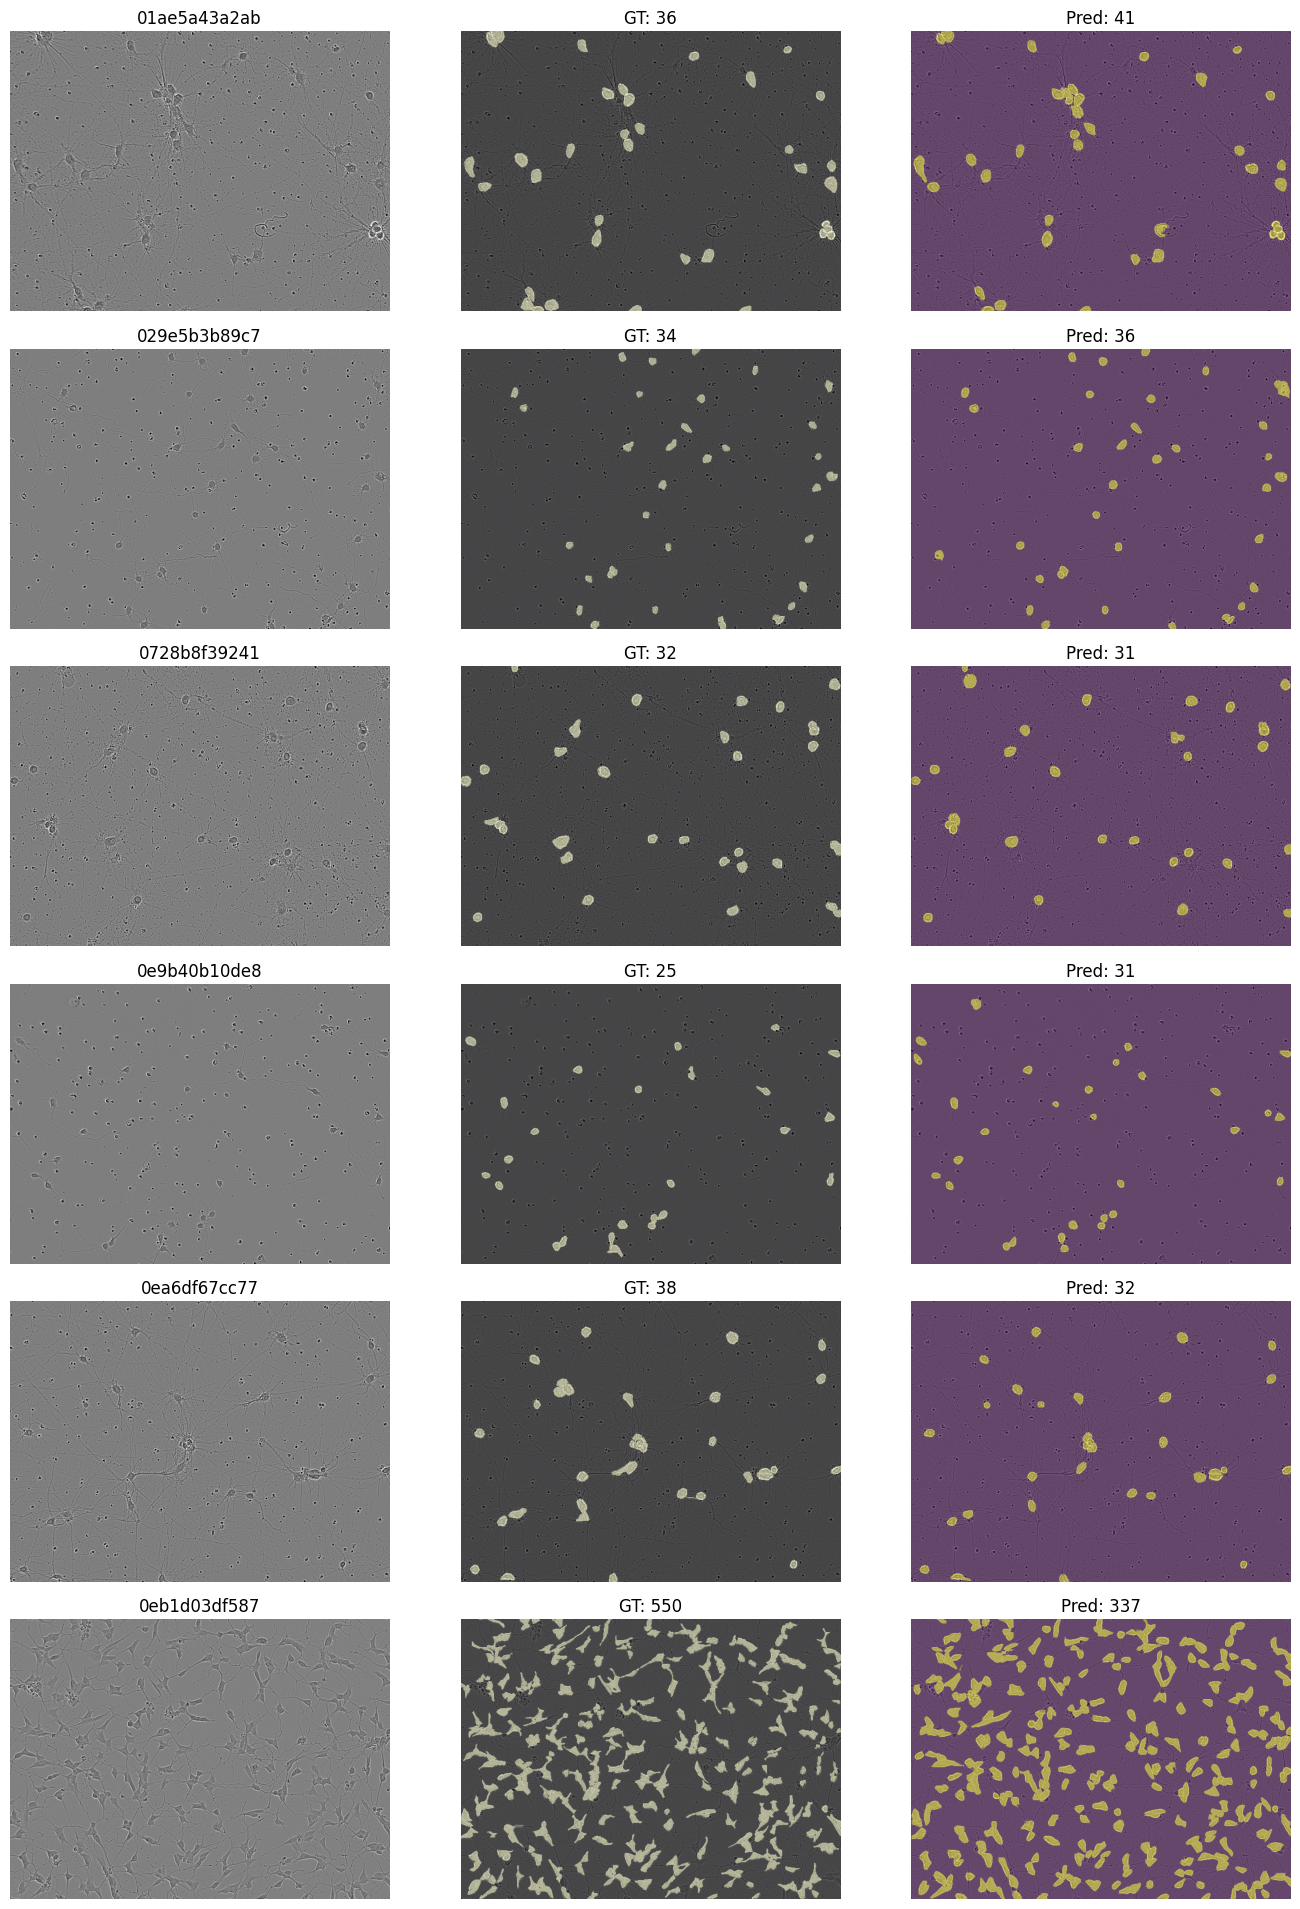

In [36]:
def entries_to_instances(image_id, post):
    built = build_instances(
        VAL_CACHE[image_id],
        post["mask_thr"],
        post["min_area"],
        CFG.IMG_H,
        CFG.IMG_W,
        post["allow_overlap"],
    )
    return [flat for score, flat in built if score >= post["score_thr"]]

visual_ids = val_ids[:6]
fig, axes = plt.subplots(len(visual_ids), 3, figsize=(14, 3.2 * len(visual_ids)))
if len(visual_ids) == 1:
    axes = np.asarray([axes])

for row_index, image_id in enumerate(visual_ids):
    post = (
        cluster_posts.get(int(CLUSTER.get(image_id, -1)), GLOBAL_POST)
        if USE_CLUSTER_POST
        else GLOBAL_POST
    )
    predictions = entries_to_instances(image_id, post)

    image = load_gray01(TRAIN_DIR / f"{image_id}.png")
    gt_union = np.zeros(NPIX, dtype=np.uint8)
    pred_union = np.zeros(NPIX, dtype=np.uint8)
    for flat in GT_VAL[image_id]:
        gt_union[flat] = 1
    for flat in predictions:
        pred_union[flat] = 1

    axes[row_index, 0].imshow(image, cmap="gray")
    axes[row_index, 0].set_title(image_id)
    axes[row_index, 1].imshow(image, cmap="gray")
    axes[row_index, 1].imshow(gt_union.reshape(CFG.IMG_H, CFG.IMG_W), alpha=0.45, cmap="magma")
    axes[row_index, 1].set_title(f"GT: {len(GT_VAL[image_id])}")
    axes[row_index, 2].imshow(image, cmap="gray")
    axes[row_index, 2].imshow(pred_union.reshape(CFG.IMG_H, CFG.IMG_W), alpha=0.45, cmap="viridis")
    axes[row_index, 2].set_title(f"Pred: {len(predictions)}")

    for axis in axes[row_index]:
        axis.axis("off")

plt.tight_layout()
plt.savefig(ART / "validation_predictions.png", dpi=120)
plt.show()


## 17 · Test inference and final submission


In [37]:
if elapsed_seconds() > CFG.TOTAL_BUDGET_SEC - 10 * 60:
    print("Warning: less than 10 minutes remain in the configured budget; starting test inference immediately.")

test_cache_start = time.time()
TEST_CACHE = cache_predictions(model, TEST_IDS, TEST_DIR)
print("test cache time:", format_duration(time.time() - test_cache_start))

submission_rows = []
prediction_counts = []
fallback_count = 0

for image_id in TEST_IDS:
    cluster_id = int(CLUSTER.get(image_id, -1))
    post = (
        cluster_posts.get(cluster_id, GLOBAL_POST)
        if USE_CLUSTER_POST
        else GLOBAL_POST
    )

    built = build_instances(
        TEST_CACHE[image_id],
        post["mask_thr"],
        post["min_area"],
        CFG.IMG_H,
        CFG.IMG_W,
        post["allow_overlap"],
    )
    instances = [
        flat
        for score, flat in built
        if score >= post["score_thr"]
    ]

    # An actual top model detection may help; an invented placeholder mask cannot.
    if not instances and CFG.FALLBACK_TO_TOP_DETECTION and TEST_CACHE[image_id]:
        fallback_built = build_instances(
            TEST_CACHE[image_id],
            mask_threshold=min(0.30, post["mask_thr"]),
            min_area=0,
            height=CFG.IMG_H,
            width=CFG.IMG_W,
            allow_overlap=False,
        )
        if fallback_built:
            instances = [fallback_built[0][1]]
            fallback_count += 1

    prediction_counts.append(len(instances))

    if not instances:
        submission_rows.append((image_id, "-1"))
    else:
        for flat in instances:
            mask = np.zeros(NPIX, dtype=np.uint8)
            mask[flat] = 1
            submission_rows.append((image_id, rle_encode(mask)))

submission = pd.DataFrame(submission_rows, columns=[ID_COL, ANN_COL])
submission.insert(0, CFG.SUB_INDEX_COL, np.arange(len(submission), dtype=np.int64))

output_path = Path("/kaggle/working/submission.csv")
submission.to_csv(output_path, index=False)
shutil.copy(output_path, ART / "submission.csv")

print("submission path   :", output_path)
print("submission columns:", submission.columns.tolist())
print("submission rows   :", len(submission))
print("fallback images   :", fallback_count)
print(
    "predictions/image:",
    {
        "mean": float(np.mean(prediction_counts)),
        "min": int(np.min(prediction_counts)),
        "max": int(np.max(prediction_counts)),
    },
)
print(submission.head(5).to_string(index=False))

assert submission.columns.tolist() == [CFG.SUB_INDEX_COL, ID_COL, ANN_COL]
assert set(submission[ID_COL].astype(str)) == set(TEST_IDS)
assert submission[CFG.SUB_INDEX_COL].is_unique
assert submission[ANN_COL].notna().all()

STATS["test_pred_counts"] = {
    "mean": float(np.mean(prediction_counts)),
    "min": int(np.min(prediction_counts)),
    "max": int(np.max(prediction_counts)),
}
STATS["fallback_images"] = int(fallback_count)


  cached 25/182
  cached 50/182
  cached 75/182
  cached 100/182
  cached 125/182
  cached 150/182
  cached 175/182
  cached 182/182
test cache time: 0h 02m
submission path   : /kaggle/working/submission.csv
submission columns: ['idx', 'id', 'annotation']
submission rows   : 18008
fallback images   : 0
predictions/image: {'mean': 98.94505494505495, 'min': 12, 'max': 529}
 idx           id                                                                                                                                                                                                               annotation
   0 0030fd0e6378                                                     39228 4 39930 7 40632 10 41335 11 42038 12 42742 13 43445 14 44149 14 44853 14 45558 13 46262 13 46966 13 47671 12 48375 11 49080 10 49784 9 50489 8 51194 6 51899 4
   1 0030fd0e6378            103415 2 104117 5 104819 7 105521 10 106224 11 106928 12 107632 13 108335 14 109039 15 109743 16 110447 17 111151 18 111856 18 

## 18 · Leaderboard probe submissions, caches, and saved model

In [38]:
# ---------------------------------------------------------------------------
# Persist everything needed to (a) re-cut the submission at any threshold without a
# GPU, (b) probe the leaderboard, (c) build a cross-notebook ensemble later.
# ---------------------------------------------------------------------------
import pickle

def write_submission(path, post, cache, ids, cluster_posts_map=None):
    rows, counts, fallbacks = [], [], 0
    for image_id in ids:
        p = post
        if cluster_posts_map:
            p = cluster_posts_map.get(int(CLUSTER.get(image_id, -1)), post)
        built = build_instances(cache[image_id], p["mask_thr"], p["min_area"],
                                CFG.IMG_H, CFG.IMG_W, p["allow_overlap"])
        instances = [flat for score, flat in built if score >= p["score_thr"]]
        if not instances and CFG.FALLBACK_TO_TOP_DETECTION and cache[image_id]:
            fb = build_instances(cache[image_id], min(0.30, p["mask_thr"]), 0,
                                 CFG.IMG_H, CFG.IMG_W, False)
            if fb:
                instances = [fb[0][1]]
                fallbacks += 1
        counts.append(len(instances))
        if not instances:
            rows.append((image_id, "-1"))
        else:
            for flat in instances:
                mask = np.zeros(NPIX, dtype=np.uint8)
                mask[flat] = 1
                rows.append((image_id, rle_encode(mask)))
    frame = pd.DataFrame(rows, columns=[ID_COL, ANN_COL])
    frame.insert(0, CFG.SUB_INDEX_COL, np.arange(len(frame), dtype=np.int64))
    frame.to_csv(path, index=False)
    assert set(frame[ID_COL].astype(str)) == set(ids)
    return dict(path=str(path), rows=len(frame), mean_pred=float(np.mean(counts)),
                fallbacks=int(fallbacks))

# --- leaderboard probe submissions -----------------------------------------
# Local validation cannot be trusted to 0.01 on ~70 images, and the Stage 2 gap
# (0.79 local vs 0.4967 public) proves it. Submitting a small score-threshold ladder
# measures the real curve on ~91 public images for the cost of a few submissions.
probe_rows = []
for delta in (0.0,) + tuple(CFG.PROBE_DELTAS):
    post = dict(GLOBAL_POST)
    post["score_thr"] = float(np.clip(round(GLOBAL_POST["score_thr"] + delta, 2), 0.02, 0.95))
    tag = "main" if delta == 0.0 else f"s{post['score_thr']:.2f}".replace(".", "")
    path = Path("/kaggle/working") / (f"submission_{CFG.RUN_TAG}_{tag}.csv")
    info = write_submission(path, post, TEST_CACHE, TEST_IDS)
    local = sweep[
        np.isclose(sweep["mask_thr"], post["mask_thr"])
        & (sweep["min_area"] == post["min_area"])
        & (sweep["allow_overlap"] == post["allow_overlap"])
        & np.isclose(sweep["score_thr"], post["score_thr"])
    ]
    probe_rows.append(dict(file=path.name, score_thr=post["score_thr"],
                           local_val_f1=float(local["f1"].iloc[0]) if len(local) else None,
                           mean_pred=round(info["mean_pred"], 1)))

# one extra shape probe: no minimum-area filter at all
_alt = dict(GLOBAL_POST); _alt["min_area"] = 0
_alt_path = Path("/kaggle/working") / f"submission_{CFG.RUN_TAG}_minarea0.csv"
_alt_info = write_submission(_alt_path, _alt, TEST_CACHE, TEST_IDS)
probe_rows.append(dict(file=_alt_path.name, score_thr=_alt["score_thr"],
                       local_val_f1=None, mean_pred=round(_alt_info["mean_pred"], 1)))

PROBES = pd.DataFrame(probe_rows)
print("\nprobe submissions written (submit these in ascending score_thr order):")
print(PROBES.to_string(index=False))
PROBES.to_csv(ART / "probe_submissions.csv", index=False)
STATS["probes"] = probe_rows

# --- caches for the ensemble and for GPU-free re-cutting --------------------
if CFG.SAVE_CACHES:
    t0 = time.time()
    with open(ART / "test_cache.pkl", "wb") as fh:
        pickle.dump(TEST_CACHE, fh, protocol=4)
    with open(ART / "val_cache.pkl", "wb") as fh:
        pickle.dump(VAL_CACHE, fh, protocol=4)
    with open(ART / "val_gt.pkl", "wb") as fh:
        pickle.dump({"gt": GT_VAL, "val_ids": val_ids, "train_ids": train_ids,
                     "post": GLOBAL_POST, "f1": GLOBAL_F1, "run_tag": CFG.RUN_TAG,
                     "min_area_grid": list(map(int, MIN_AREA_GRID))}, fh, protocol=4)
    torch.save({"model": model.state_dict(),
                "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()}},
               ART / "selected_model.pt")
    print(f"\ncaches + model written in {time.time() - t0:.0f}s:",
          [p.name for p in sorted(ART.iterdir())])



probe submissions written (submit these in ascending score_thr order):
                                               file  score_thr  local_val_f1  mean_pred
    submission_stage4_imagenet_r50v2_hires_main.csv       0.26      0.750732       98.9
    submission_stage4_imagenet_r50v2_hires_s014.csv       0.14      0.733799      116.8
    submission_stage4_imagenet_r50v2_hires_s020.csv       0.20      0.747239      106.9
    submission_stage4_imagenet_r50v2_hires_s032.csv       0.32      0.749189       92.3
    submission_stage4_imagenet_r50v2_hires_s038.csv       0.38      0.742937       85.8
submission_stage4_imagenet_r50v2_hires_minarea0.csv       0.26           NaN      131.6

caches + model written in 2s: ['REPORT.md', 'eda_statistics.png', 'probe_submissions.csv', 'run_stats.json', 'selected_model.pt', 'submission.csv', 'sweep_per_image.csv', 'sweep_results.csv', 'test_cache.pkl', 'training_log.csv', 'val_cache.pkl', 'val_gt.pkl', 'validation_predictions.png']


## 18 · Final report and artifacts


In [39]:
STATS["cfg"] = {
    key: str(value)
    for key, value in vars(CFG).items()
    if key.isupper()
}
STATS["training_log"] = training_log
STATS["elapsed_seconds"] = float(elapsed_seconds())

with open(ART / "run_stats.json", "w") as file:
    json.dump(STATS, file, indent=2, default=str)

report_lines = [
    "# Stage 2 Run Report",
    "",
    f"- Architecture: {CFG.ARCH}",
    f"- Weights: {CFG.WEIGHTS_MODE}",
    f"- Mask loss: {CFG.MASK_LOSS}",
    f"- Official metric: per-image instance F1 at Dice ≥ {CFG.DICE_MATCH_THR}",
    f"- Train/validation images: {len(train_ids)}/{len(val_ids)}",
    f"- Detection capacity: {CFG.BOX_DET_PER_IMG}",
    f"- Anchors: {CFG.ANCHOR_SIZES}",
    f"- Anchor scale correction: {STATS['anchor_scale']:.3f}",
    f"- Best checkpoint F1 during training: {STATS.get('best_val_score_during_training')}",
    f"- Best global sweep F1: {GLOBAL_F1:.6f}",
    f"- Global post-processing: {GLOBAL_POST}",
    f"- Cluster post-processing used: {USE_CLUSTER_POST}",
    f"- Cluster validation F1: {CLUSTER_F1}",
    f"- Test predictions/image: {STATS['test_pred_counts']}",
    f"- Fallback images: {STATS['fallback_images']}",
    f"- Total elapsed: {format_duration(elapsed_seconds())}",
    "",
    "## Submit",
    "",
    "`/kaggle/working/submission.csv`",
]

report_text = "\n".join(report_lines)
(ART / "REPORT.md").write_text(report_text)
print(report_text)

print("\nArtifacts:")
for path in sorted(ART.iterdir()):
    print(" ", path.name)


# Stage 2 Run Report

- Architecture: v2
- Weights: coco
- Mask loss: bce+dice
- Official metric: per-image instance F1 at Dice ≥ 0.5
- Train/validation images: 338/86
- Detection capacity: 1000
- Anchors: ((20,), (24,), (32,), (44,), (96,))
- Anchor scale correction: 1.631
- Best checkpoint F1 during training: 0.7313824256247006
- Best global sweep F1: 0.750732
- Global post-processing: {'mask_thr': 0.6, 'min_area': 103, 'allow_overlap': False, 'score_thr': 0.26}
- Cluster post-processing used: False
- Cluster validation F1: 0.7520512883576381
- Test predictions/image: {'mean': 98.94505494505495, 'min': 12, 'max': 529}
- Fallback images: 0
- Total elapsed: 2h 17m

## Submit

`/kaggle/working/submission.csv`

Artifacts:
  REPORT.md
  eda_statistics.png
  probe_submissions.csv
  run_stats.json
  selected_model.pt
  submission.csv
  sweep_per_image.csv
  sweep_results.csv
  test_cache.pkl
  training_log.csv
  val_cache.pkl
  val_gt.pkl
  validation_predictions.png


## 20 · Report addendum

In [40]:
lines = [
    "",
    "## Stage 3/4 additions",
    f"- run tag: {CFG.RUN_TAG}",
    f"- weights: {CFG.WEIGHTS_MODE} | arch: {CFG.ARCH} | seed: {CFG.SEED}",
    f"- grouped split: {CFG.GROUP_SPLIT} | groups: {STATS.get('n_groups')} | fold {CFG.FOLD}/{CFG.N_FOLDS}",
    f"- max val-to-train thumbnail correlation: {STATS.get('max_val_train_corr'):.3f} "
    f"(mean {STATS.get('mean_val_train_corr'):.3f})",
    f"- train/val images: {len(train_ids)}/{len(val_ids)}",
    f"- detections per image: {CFG.BOX_DET_PER_IMG} | instance cap: {CFG.MAX_INSTANCES_TRAIN}",
    f"- HONEST validation F1: {GLOBAL_F1:.4f}   <-- compare with Stage 2's leaky 0.7909",
    f"- chosen post-processing: {GLOBAL_POST}",
    "",
    "### Probe submissions",
    PROBES.to_string(index=False),
    "",
    "Submit the ladder in ascending score_thr order, record the public score of each,",
    "then keep the threshold at the centre of the best region rather than its peak.",
]
with open(ART / "REPORT.md", "a") as fh:
    fh.write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nartifacts:", [p.name for p in sorted(ART.iterdir())])



## Stage 3/4 additions
- run tag: stage4_imagenet_r50v2_hires
- weights: coco | arch: v2 | seed: 777
- grouped split: True | groups: 421 | fold 0/5
- max val-to-train thumbnail correlation: 0.665 (mean 0.076)
- train/val images: 338/86
- detections per image: 1000 | instance cap: None
- HONEST validation F1: 0.7507   <-- compare with Stage 2's leaky 0.7909
- chosen post-processing: {'mask_thr': 0.6, 'min_area': 103, 'allow_overlap': False, 'score_thr': 0.26}

### Probe submissions
                                               file  score_thr  local_val_f1  mean_pred
    submission_stage4_imagenet_r50v2_hires_main.csv       0.26      0.750732       98.9
    submission_stage4_imagenet_r50v2_hires_s014.csv       0.14      0.733799      116.8
    submission_stage4_imagenet_r50v2_hires_s020.csv       0.20      0.747239      106.9
    submission_stage4_imagenet_r50v2_hires_s032.csv       0.32      0.749189       92.3
    submission_stage4_imagenet_r50v2_hires_s038.csv       0.38      0.742

## 21 · Optional ensemble with the Stage 3 run

In [41]:
# ---------------------------------------------------------------------------
# Optional cross-notebook ensemble.
#
# To enable: in this notebook's sidebar choose  Add Data -> Your Work -> Notebook
# Output, and add the Stage 3 run.  This cell then finds its caches automatically.
#
# Both notebooks validate on the SAME fold, so the ensemble threshold is tuned on
# images neither model trained on.  Merging is just concatenation by score: the
# non-overlap painting in build_instances already suppresses duplicates, because a
# second model's copy of an instance loses its pixels to the higher-scoring one and
# then falls below min_area.
# ---------------------------------------------------------------------------
import pickle

partner_dir = None
for candidate in sorted(Path("/kaggle/input").rglob("test_cache.pkl")):
    partner_dir = candidate.parent
    break

if partner_dir is None:
    print("No partner cache found under /kaggle/input -> skipping the ensemble.")
    print("Run this notebook again with the Stage 3 output attached to enable it.")
else:
    print("partner artefacts:", partner_dir)
    with open(partner_dir / "val_cache.pkl", "rb") as fh:
        PARTNER_VAL = pickle.load(fh)
    with open(partner_dir / "test_cache.pkl", "rb") as fh:
        PARTNER_TEST = pickle.load(fh)
    with open(partner_dir / "val_gt.pkl", "rb") as fh:
        PARTNER_META = pickle.load(fh)

    print("partner run tag :", PARTNER_META.get("run_tag"))
    print("partner val F1  :", PARTNER_META.get("f1"))

    same_fold = set(PARTNER_META["val_ids"]) == set(val_ids)
    print("same validation fold:", same_fold)
    if not same_fold:
        print("!! Folds differ - the ensemble threshold would be tuned on images the "
              "partner trained on. Refusing to ensemble.")
    else:
        def merged(a, b):
            return sorted(list(a) + list(b), key=lambda item: -item[0])

        ENS_VAL = {i: merged(VAL_CACHE[i], PARTNER_VAL[i]) for i in val_ids}

        ens_rows = []
        for mask_threshold in (0.40, 0.50, 0.60):
            for min_area in MIN_AREA_GRID:
                results, _, _ = evaluate_cached_predictions(
                    cache=ENS_VAL, ids=val_ids, gt_by_id=GT_VAL,
                    mask_threshold=mask_threshold, min_area=min_area,
                    allow_overlap=False, score_grid=CFG.SWEEP_SCORE_THR,
                )
                for result in results:
                    ens_rows.append(dict(mask_thr=float(mask_threshold),
                                         min_area=int(min_area),
                                         allow_overlap=False,
                                         score_thr=float(result["score_thr"]),
                                         f1=float(result["f1"]),
                                         mean_predictions=float(result["mean_predictions"])))
        ens_sweep = pd.DataFrame(ens_rows).sort_values("f1", ascending=False).reset_index(drop=True)
        ens_sweep.to_csv(ART / "ensemble_sweep.csv", index=False)
        print(ens_sweep.head(10).to_string(index=False))

        top = ens_sweep.iloc[0]
        same_shape = ens_sweep[
            np.isclose(ens_sweep["mask_thr"], top.mask_thr)
            & (ens_sweep["min_area"] == top.min_area)
        ].sort_values("score_thr")
        plateau = same_shape[same_shape["f1"] >= top.f1 - CFG.ROBUST_TOL]
        grid = same_shape["score_thr"].to_numpy()
        chosen = float(grid[np.argmin(np.abs(grid - float(np.median(plateau["score_thr"]))))])
        ENS_POST = dict(mask_thr=float(top.mask_thr), min_area=int(top.min_area),
                        allow_overlap=False, score_thr=chosen)
        ENS_F1 = float(same_shape[np.isclose(same_shape["score_thr"], chosen)]["f1"].iloc[0])

        print("\nthis model alone  :", round(GLOBAL_F1, 4))
        print("partner alone     :", round(float(PARTNER_META.get("f1", float('nan'))), 4))
        print("ensemble          :", round(ENS_F1, 4), ENS_POST)

        best_single = max(GLOBAL_F1, float(PARTNER_META.get("f1", -1)))
        if ENS_F1 > best_single + 0.002:
            ENS_TEST = {i: merged(TEST_CACHE[i], PARTNER_TEST[i]) for i in TEST_IDS}
            info = write_submission(Path("/kaggle/working/submission_ensemble.csv"),
                                    ENS_POST, ENS_TEST, TEST_IDS)
            for delta in (-0.08, 0.08):
                post = dict(ENS_POST)
                post["score_thr"] = float(np.clip(round(ENS_POST["score_thr"] + delta, 2), 0.02, 0.95))
                suffix = f"{post['score_thr']:.2f}".replace(".", "")
                write_submission(Path("/kaggle/working") / f"submission_ensemble_s{suffix}.csv",
                                 post, ENS_TEST, TEST_IDS)
            print("\nensemble submission written:", info)
        else:
            print("\nEnsemble does not clear the single best model by 0.002 -> not written.")
            print("Submit the stronger single model instead.")

        STATS["ensemble_f1"] = ENS_F1
        STATS["ensemble_post"] = ENS_POST


No partner cache found under /kaggle/input -> skipping the ensemble.
Run this notebook again with the Stage 3 output attached to enable it.
